## Первичный анализ

<font size="4">

### Импорт библиотек и загрузка датасета

</font>

In [1]:
# Стандарт
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# доп., для красоты
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import plotly.graph_objects as go
import plotly.express as px

# статистические тесты
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Предобработка и Pipeline
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Обучение моделей
import joblib
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (make_scorer, accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

df = pd.read_csv('https://raw.githubusercontent.com/STEPANPROTSKY/MLandDA/main/Datasets/student_dropout_risk_2026.csv')

<font size="4">

### Структура и дубликаты

</font>

In [2]:
df.head()

,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,1,23,Male,Brazil,0,0,Low,1,0,1,...,4,16.3,0,3,8,0,6,37,5.7,0
1,2,18,Other,USA,1,1,High,1,1,0,...,3,8.4,1,1,7,0,6,15,5.4,1
2,3,24,Other,USA,0,0,High,0,1,1,...,3,11.3,1,0,2,0,3,4,4.3,0
3,4,25,Female,USA,0,1,Middle,1,1,0,...,2,13.2,1,1,5,0,7,10,6.7,0
4,5,15,Female,Canada,0,0,Low,1,1,0,...,4,7.4,1,0,7,0,10,24,5.8,0


In [3]:
df_ = df.copy()
df_.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 34 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   person_id                     100000 non-null  int64  
 1   age                           100000 non-null  int64  
 2   gender                        100000 non-null  object 
 3   nationality                   100000 non-null  object 
 4   first_generation              100000 non-null  int64  
 5   disability_status             100000 non-null  int64  
 6   family_income_level           100000 non-null  object 
 7   scholarship_holder            100000 non-null  int64  
 8   tuition_up_to_date            100000 non-null  int64  
 9   part_time_job                 100000 non-null  int64  
 10  weekly_work_hours             100000 non-null  int64  
 11  course_type                   100000 non-null  object 
 12  study_mode                    100000 non-null

<font size="4">

Датасет размером 100000 х 34: 33 признака + таргет `dropout`. Все столбцы заполнены (100000 non-null), 5 строковых столбцов - категориальные признаки, остальные числовые, среди них 8 бинарных 0/1

</font>

In [4]:
df_.duplicated().sum()

np.int64(0)

<font size="4">
    
Имеется нулевое кол-во дублей

<font/>

In [5]:
# убираем признак "id" за ненадобностью
df_.drop(columns='person_id', axis=1, inplace=True)

In [6]:
# категориальные признаки
cat = ['gender', 'nationality', 'family_income_level', 'course_type', 'study_mode']

# бинарные 0/1
binary = ['first_generation', 'disability_status', 'scholarship_holder', 'tuition_up_to_date',
               'part_time_job', 'international_student', 'extracurricular_activities', 'mental_health_support']

# числовые: всё остальное, кроме таргета
num = [col for col in df_.columns if col not in cat + binary + ['dropout']]

In [7]:
def describe_extended(df, columns, iqr_k=1.5):
    """
    Расширенный describe: стандартная таблица describe() + характеристики,
    которые не хочется считать в ручную...

    Параметры:
    df : pandas.DataFrame
        датафрейм с признаками
    columns : list
        числовые признаки
    iqr_k : float, по умолчанию 1.5
        множитель IQR для границ Тьюки

    Возвращает:
    pandas.DataFrame - одна строка на признак
    """
    
    data = df[columns]
    desc = data.describe().T

    q1, median, q3 = desc['25%'], desc['50%'], desc['75%']

    # межквартильный размах: ширина «середины» распределения (50% значений)
    # в отличие от std не чувствителен к выбросам, поэтому на нем строятся границы Тьюки
    iqr = q3 - q1

    # коэффициент асимметрии Пирсона: 3 * (mean - median) / std
    desc['pearson_skew'] = 3 * (desc['mean'] - median) / desc['std']

    # границы Тьюки (Q1 - 1.5 * IQR, Q3 + 1.5 * IQR): значения за ними формально считаются выбросами
    # если нижняя граница меньше min (или верхняя больше max), выбросов с этой стороны нет
    desc['tukey_low'] = q1 - iqr_k * iqr
    desc['tukey_high'] = q3 + iqr_k * iqr

    # стандартная ошибка среднего: std / sqrt(n) - промежуточное число для доверительного интервала,
    se_mean = desc['std'] / np.sqrt(desc['count'])

    # 95% доверительный интервал для среднего: mean +- 1.96 * SE
    desc['ci95_low'] = desc['mean'] - 1.96 * se_mean
    desc['ci95_high'] = desc['mean'] + 1.96 * se_mean

    return desc.round(3)


# показываем все столбцы таблицы
with pd.option_context('display.max_columns', None, 'display.width', None):
    display(describe_extended(df_, num))


,count,mean,std,min,25%,50%,75%,max,pearson_skew,tukey_low,tukey_high,ci95_low,ci95_high
age,100000.0,21.521,3.399,15.0,19.00,21.00,24.00,30.0,0.460,11.50,31.50,21.500,21.542
weekly_work_hours,100000.0,8.745,10.233,0.0,0.00,0.00,18.00,40.0,2.564,-27.00,45.00,8.681,8.808
semester,100000.0,3.618,2.113,1.0,2.00,3.00,5.00,8.0,0.877,-2.50,9.50,3.605,3.631
admission_grade,100000.0,133.146,28.256,5.5,114.10,133.10,152.50,200.0,0.005,56.50,210.10,132.970,133.321
previous_qualification_grade,100000.0,139.444,25.122,30.2,122.30,139.60,156.60,200.0,-0.019,70.85,208.05,139.288,139.599
units_enrolled,100000.0,13.045,3.822,1.0,10.00,13.00,16.00,24.0,0.036,1.00,25.00,13.022,13.069
units_passed,100000.0,10.328,3.652,1.0,8.00,10.00,13.00,24.0,0.269,0.50,20.50,10.305,10.350
units_failed,100000.0,2.718,2.215,0.0,1.00,2.00,4.00,17.0,0.972,-3.50,8.50,2.704,2.732
gpa_semester_1,100000.0,2.568,0.789,0.0,2.03,2.58,3.13,4.0,-0.046,0.38,4.78,2.563,2.573
gpa_semester_2,100000.0,1.981,0.718,0.0,1.49,1.99,2.49,4.0,-0.038,-0.01,3.99,1.976,1.985


<font size="4">

По числовым признакам:<br>

- `age` - студенты от 15 до 30 лет, медиана 21, среднее чуть выше медианы (асимметрия Пирсона 0.46) - распределение почти симметричное со слабым хвостом вправо. Выбросов по Тьюки нет. Настораживает нижняя граница: 15-летние студенты для университета выглядят странно<br>

- `weekly_work_hours` - Q1 и медиана равны 0, то есть как минимум половина студентов не работает. Отсюда и самая большая асимметрия Пирсона (2.56): ее дает не длинный хвост, а масса нулей. Верхняя граница Тьюки (45) выше максимума (40), выбросов нет. По сути это смесь двух групп: неработающие и работающие<br>

- `semester` - от 1 до 8, медиана 3, хвост вправо (0.88): на младших семестрах студентов больше, до старших доходят не все<br>

- `admission_grade` и `previous_qualification_grade` - шкала до 200, среднее почти совпадает с медианой (133 и 139.5), асимметрии нет. Нижняя граница Тьюки (56.5 и 70.9) выше минимума (5.5 и 30.2) - есть единичные очень низкие баллы. Максимум ровно 200 - край шкалы<br>

- `units_enrolled` симметричный (0.04), `units_passed` - небольшой хвост вправо, `units_failed` - заметный хвост вправо (0.97): у половины студентов 1-4 несданных дисциплины, но максимум 17 при верхней границе Тьюки 8.5. Такие значения правдоподобны, это не ошибки<br>

- `gpa_semester_1` - шкала 0-4, симметричный (-0.05), медиана 2.58. Нижняя граница Тьюки 0.38 - нулевой GPA встречается, но редко. Максимум 4.0 - край шкалы<br>

- `gpa_semester_2` - той же формы, но весь сдвинут вниз: среднее 1.98 против 2.57 в первом семестре. Доверительные интервалы средних очень узкие (+-0.005), так что это не случайность - во втором семестре оценки систематически ниже<br>

- `attendance_rate` и `assignments_submitted_rate` - медиана выше среднего, слабый хвост влево (-0.17 и -0.18). Q3 (89 и 87.2) близко к 100%, то есть четверть студентов почти у верхней границы. Нижняя граница Тьюки (24.3 и 13.7) выше нуля - единичные студенты почти не ходят и не сдают задания<br>

- `library_visits_per_month`, `missed_deadlines`, `commute_time_mins` - счетные и временные признаки с длинным правым хвостом: максимум (30, 20, 120) намного выше верхней границы Тьюки (12, 7.5, 73.5). У `missed_deadlines` Q1 = 0 - у четверти студентов нет ни одного пропущенного дедлайна, поэтому асимметрия Пирсона у него небольшая (0.43), хотя хвост длинный<br>

- `lms_logins_per_week` - почти симметричный (0.13), но максимум 29.6 при верхней границе 17.8 - есть студенты, которые заходят в LMS намного чаще остальных<br>

- `stress_level` и `satisfaction_score` - ограниченные шкалы 1-10, выбросов быть не может. У стресса медиана 7 выше среднего (хвост влево, -0.77) - большинство студентов оценивают стресс как высокий<br>

- `sleep_hours` - от 4 до 10 часов, медиана 6.5, симметричный (0.14), выбросы только на самом краю (10 часов при границе 9.95)<br>

Предварительно:

- Невозможных значений нет: отрицательных чисел, процентов больше 100, GPA больше 4 или баллов больше 200 не встречается. Все выбросы по Тьюки - правдоподобные значения (много несданных дисциплин, долгая дорога), удалять их не будем
- Признаки с длинным правым хвостом (`library_visits_per_month`, `missed_deadlines`, `commute_time_mins`, `units_failed`) - нужно ли их преобразовывать, решим не по форме распределения, а по тому, линейно ли меняется логит отчисления (логистической регрессии нормальность признаков не нужна)
- `weekly_work_hours` - смесь «0 часов» и «5-40 часов», стоит посмотреть, отличаются ли неработающие от работающих скачком или риск растет плавно с каждым часом
- Максимумы GPA, посещаемости, сданных заданий и баллов совпадают с краем шкалы, а у возраста минимум 15 выглядит неправдоподобно - проверим на гистограммах, не обрезаны ли значения
- Шкалы признаков сильно отличаются (GPA 0-4, баллы 0-200, дорога 0-120 мин), поэтому перед логистической регрессией с регуляризацией нужен StandardScaler, иначе штраф будет действовать на признаки неравномерно, а коэффициенты нельзя будет сравнивать
- Доверительные интервалы средних при n = 100000 очень узкие, поэтому любые заметные различия средних между группами будут статистически значимы - смотреть нужно на размер различий

</font>

<font size="4">

### Анализ пропусков

<font/>

In [8]:
df_.isna().sum()

age                             0
gender                          0
nationality                     0
first_generation                0
disability_status               0
family_income_level             0
scholarship_holder              0
tuition_up_to_date              0
part_time_job                   0
weekly_work_hours               0
course_type                     0
study_mode                      0
semester                        0
international_student           0
admission_grade                 0
previous_qualification_grade    0
units_enrolled                  0
units_passed                    0
units_failed                    0
gpa_semester_1                  0
gpa_semester_2                  0
attendance_rate                 0
assignments_submitted_rate      0
library_visits_per_month        0
lms_logins_per_week             0
extracurricular_activities      0
missed_deadlines                0
stress_level                    0
mental_health_support           0
satisfaction_s

<font size="4">

Пропусков нет

</font>

### Логическая согласованность данных

<font size="4">

По скольку 'All records are fully synthetic - no real student data is present', то стоит проверить, не противоречат ли признаки друг другу и здравому смыслу:

1. `units_passed + units_failed == units_enrolled` - если это тождество, три признака линейно зависимы, и для логистической регрессии это важно
2. `part_time_job` и `weekly_work_hours` - подработка без рабочих часов и наоборот
3. Возраст и семестр - 15-летний студент на 8-м семестре выглядит странно
4. `international_student` и `nationality` - иностранный студент из той же страны, что и большинство
5. Как соотносятся `gpa_semester_1` и `gpa_semester_2`

</font>

In [9]:
# 1. тождество по дисциплинам
units_ok = (df_['units_passed'] + df_['units_failed'] == df_['units_enrolled']).mean()
print(f'1. passed + failed == enrolled: {units_ok:.2%} строк')

# 2. подработка и часы
job_ok = (df_['part_time_job'] == (df_['weekly_work_hours'] > 0).astype(int)).mean()
print(f'2. part_time_job == (weekly_work_hours > 0): {job_ok:.2%} строк, '
      f'минимум часов у работающих: {df_.loc[df_["part_time_job"] == 1, "weekly_work_hours"].min()}')

# 3. возраст и семестр
young = df_['age'] < 17
print(f'3. студентов младше 17: {young.sum()} ({young.mean():.2%}), '
      f'из них 15-летних на 8 семестре: {((df_["age"] == 15) & (df_["semester"] == 8)).sum()}, '
      f'корреляция age и semester: {df_["age"].corr(df_["semester"]):.3f}')

# 4. доля иностранных студентов по странам
print('4. доля international_student по странам:')
print(df_.groupby('nationality')['international_student'].mean().round(3).sort_values().to_string())

# 5. первый и второй семестр
gpa_diff = df_['gpa_semester_2'] - df_['gpa_semester_1']
print(f'5. gpa_semester_2 > gpa_semester_1: {(gpa_diff > 0).mean():.2%}, средняя разница: {gpa_diff.mean():.2f}')

1. passed + failed == enrolled: 100.00% строк
2. part_time_job == (weekly_work_hours > 0): 100.00% строк, минимум часов у работающих: 5
3. студентов младше 17: 7753 (7.75%), из них 15-летних на 8 семестре: 232, корреляция age и semester: 0.006
4. доля international_student по странам:
nationality
Nigeria        0.170
Australia      0.173
Philippines    0.173
Germany        0.173
India          0.178
Pakistan       0.178
Mexico         0.180
China          0.182
USA            0.183
Egypt          0.183
Brazil         0.183
South Korea    0.186
UK             0.187
Canada         0.187
Indonesia      0.191
5. gpa_semester_2 > gpa_semester_1: 9.12%, средняя разница: -0.59


<font size="4">

- Тождество `units_passed + units_failed = units_enrolled` выполняется в 100% строк. Три признака линейно зависимы: любой из них - точная комбинация двух других. В модель нельзя подавать все три сразу, иначе коэффициенты не определены однозначно (см. VIF ниже)
- `part_time_job` в точности равен `weekly_work_hours > 0`, у работающих минимум 5 часов. Бинарный признак может добавить к часам только «скачок» между 0 и 5 часами - проверим на графиках логитов
- Возраст не связан с семестром (корреляция 0.006): 15-летних на 8-м семестре 232 человека. Возраст сгенерирован независимо от остальных признаков
- Доля иностранных студентов одинаковая (~18%) во всех странах, в том числе в USA. В реальности `international_student` зависел бы от страны, здесь он тоже сгенерирован независимо
- Во втором семестре GPA выше только у 9.1% студентов, в среднем он ниже на 0.59. Возможно, так задумано («второй семестр сложнее»), но выглядит скорее как особенность генератора

Строки не удаляем: данные синтетические, «правильных» значений вместо странных у нас нет, а удаление 7.8% «слишком молодых» студентов исказило бы распределения других признаков. Просто помним, что выводы относятся к датасету, а не к реальным студентам

</font>

### Таргетный признак

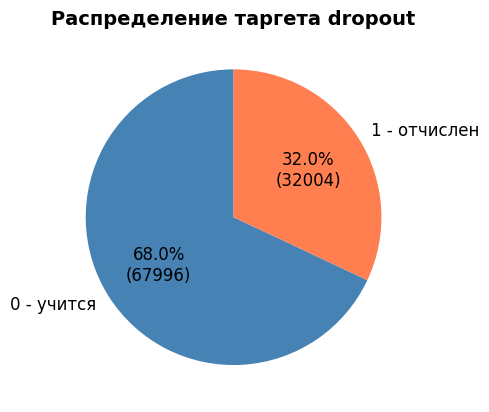

In [10]:
counts = df_['dropout'].value_counts().sort_index()

# autopct подписывает каждый сектор: доля в % и количество студентов (pct - доля сектора в процентах)
plt.pie(counts, labels=['0 - учится', '1 - отчислен'], colors=['steelblue', 'coral'], startangle=90,
        autopct=lambda pct: f'{pct:.1f}%\n({pct * counts.sum() / 100:.0f})', textprops={'fontsize': 12})
plt.title('Распределение таргета dropout', fontsize=14, fontweight='bold')
plt.show()

<font size="4">

Отчислено 32004 студента (32.0%), не отчислено 67996 (68.0%), соотношение ~2.1 : 1. Дисбаланс умеренный, но для выбора метрик он важен:

- Модель, которая всегда говорит «не отчислится», получит accuracy 0.68, не найдя ни одного отчисленного. Поэтому accuracy сама по себе ничего не скажет
- Смотрим recall, precision и F1 по классу 1, ROC-AUC и PR-AUC. У случайной модели PR-AUC равен доле положительного класса, то есть 0.32 - это и есть нижняя планка
- train / test разбиваем со `stratify=y`, чтобы в обеих выборках было по 32% отчисленных
- Порог 0.5 не обязан быть лучшим: при дисбалансе и разной цене FN / FP threshold нужно подбирать (на validation)

</font>

## EDA

### Распределения у числовых признаков

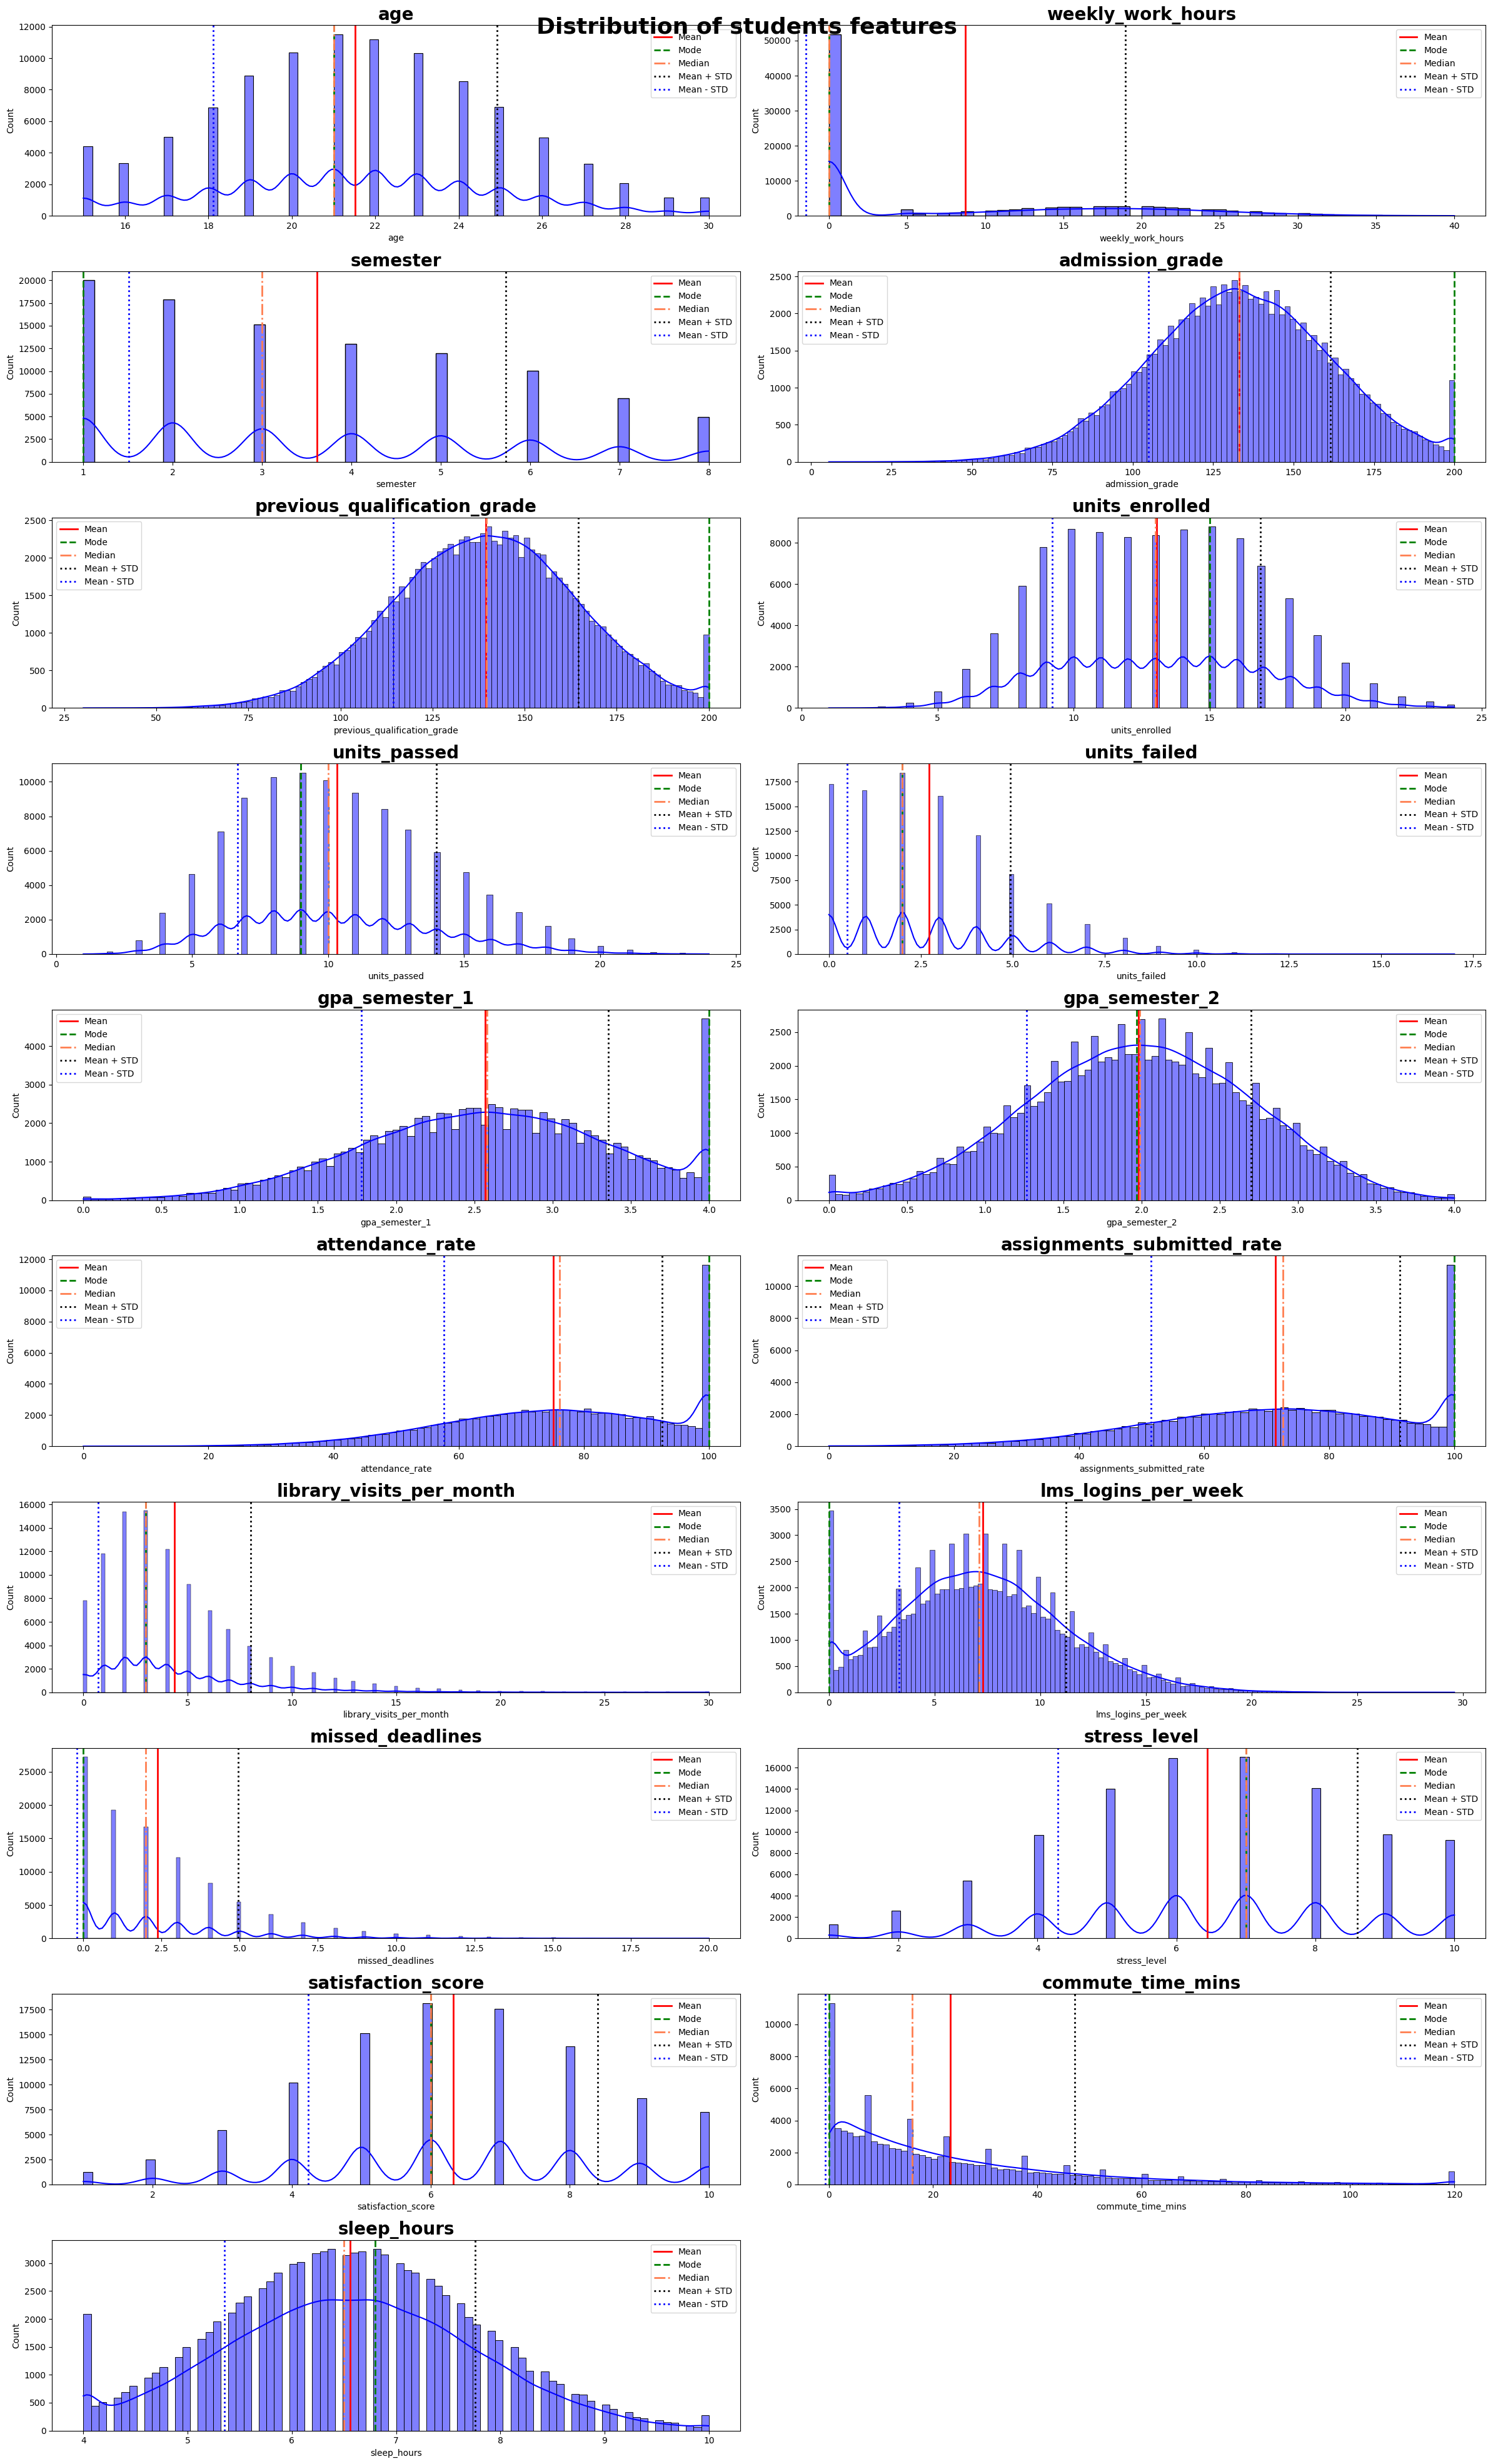

In [11]:
def plot_numeric_distributions(df, columns, n_cols=2):
    """
    Строит распределения числовых признаков с помощью гистограмм и KDE-кривых

    Параметры:
    df : pandas.DataFrame
        датафрейм, содержащий числовые признаки для анализа

    columns : list
        список названий числовых признаков, для которых необходимо построить распределения

    n_cols : int, по умолчанию 2
        количество графиков в одной строке

    Что рассчитывается:
    для каждого числового признака рассчитываются:
        - среднее значение (Mean);
        - мода (Mode);
        - медиана (Median);
        - стандартное отклонение (STD).

    Что строится:
    для каждого признака строится:
        - гистограмма распределения значений;
        - KDE-кривая плотности;
        - вертикальная линия среднего значения;
        - вертикальная линия моды;
        - вертикальная линия медианы;
        - границы Mean + STD и Mean - STD."""

    # рассчитываем количество строк графиков
    n_rows = (len(columns) + n_cols - 1) // n_cols

    # создаем общую область для всех графиков
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(24, 4 * n_rows))

    # приводим axes к одномерному массиву, что позволяет одинаково работать с любым количеством графиков
    axes = np.atleast_1d(axes).flatten()

    # строим график для каждого числового признака
    for ax, col in zip(axes, columns):
        # рассчитываем основные статистические показатели
        mean = df[col].mean()
        mode = df[col].mode().iloc[0]
        median = df[col].median()
        std = df[col].std()

        # строим гистограмму и KDE-кривую распределения
        sns.histplot(
            data=df,
            x=col,
            kde=True,
            color='blue',
            ax=ax)

        # описываем статистические линии: значение, цвет, стиль линии, название
        lines = [
            (mean, 'red', '-', 'Mean'),
            (mode, 'green', '--', 'Mode'),
            (median, 'coral', '-.', 'Median'),
            (mean + std, 'black', ':', 'Mean + STD'),
            (mean - std, 'blue', ':', 'Mean - STD')]

        # добавляем вертикальные линии на график
        for value, color, linestyle, label in lines:
            ax.axvline(
                value,
                color=color,
                linestyle=linestyle,
                linewidth=2,
                label=label)

        # настраиваем заголовок графика
        ax.set_title(
            col,
            fontsize=20,
            fontweight='bold')

        # добавляем легенду
        ax.legend()

    # удаляем пустые графики, если количество признаков не кратно n_cols
    for ax in axes[len(columns):]:
        fig.delaxes(ax)

    # добавляем общий заголовок
    fig.suptitle(
        'Distribution of students features',
        fontsize=26,
        fontweight='bold')

    # автоматически регулируем расположение элементов
    plt.tight_layout()

    # отображаем графики
    plt.show()

plot_numeric_distributions(df_, num)

<font size="4">

Анализ распределений числовых признаков

Нормальных распределений почти нет, и форма у признаков разная:
- Симметричные, близкие к колоколу: `admission_grade`, `previous_qualification_grade`, `gpa_semester_1`, `gpa_semester_2`, `units_enrolled`, `lms_logins_per_week`, `sleep_hours`. У GPA, баллов и сна заметен «столбик» на границе диапазона - след обрезки
- Скошенные влево с пиком на 100%: `attendance_rate`, `assignments_submitted_rate`
- Скошенные вправо, счётные: `units_failed`, `missed_deadlines`, `library_visits_per_month`, `commute_time_mins` - много нулей и длинный хвост
- Смесь двух групп: `weekly_work_hours` - пик в нуле (не работают) и отдельный «горб» 5-40 часов (работают). Mean и median тут ничего не описывают
- Дискретные шкалы: `age`, `semester`, `stress_level`, `satisfaction_score`

Логистической регрессии нормальность признаков не нужна. Ей нужно, чтобы **логарифм шансов** (log-odds) отчисления менялся с признаком линейно. Длинные хвосты могут этому мешать: если эффект «насыщается» (первый пропущенный дедлайн важнее двадцатого), модель с линейным признаком переоценит хвост. Это проверим отдельно графиками логитов

</font>

### Распределение у категориальных признаков

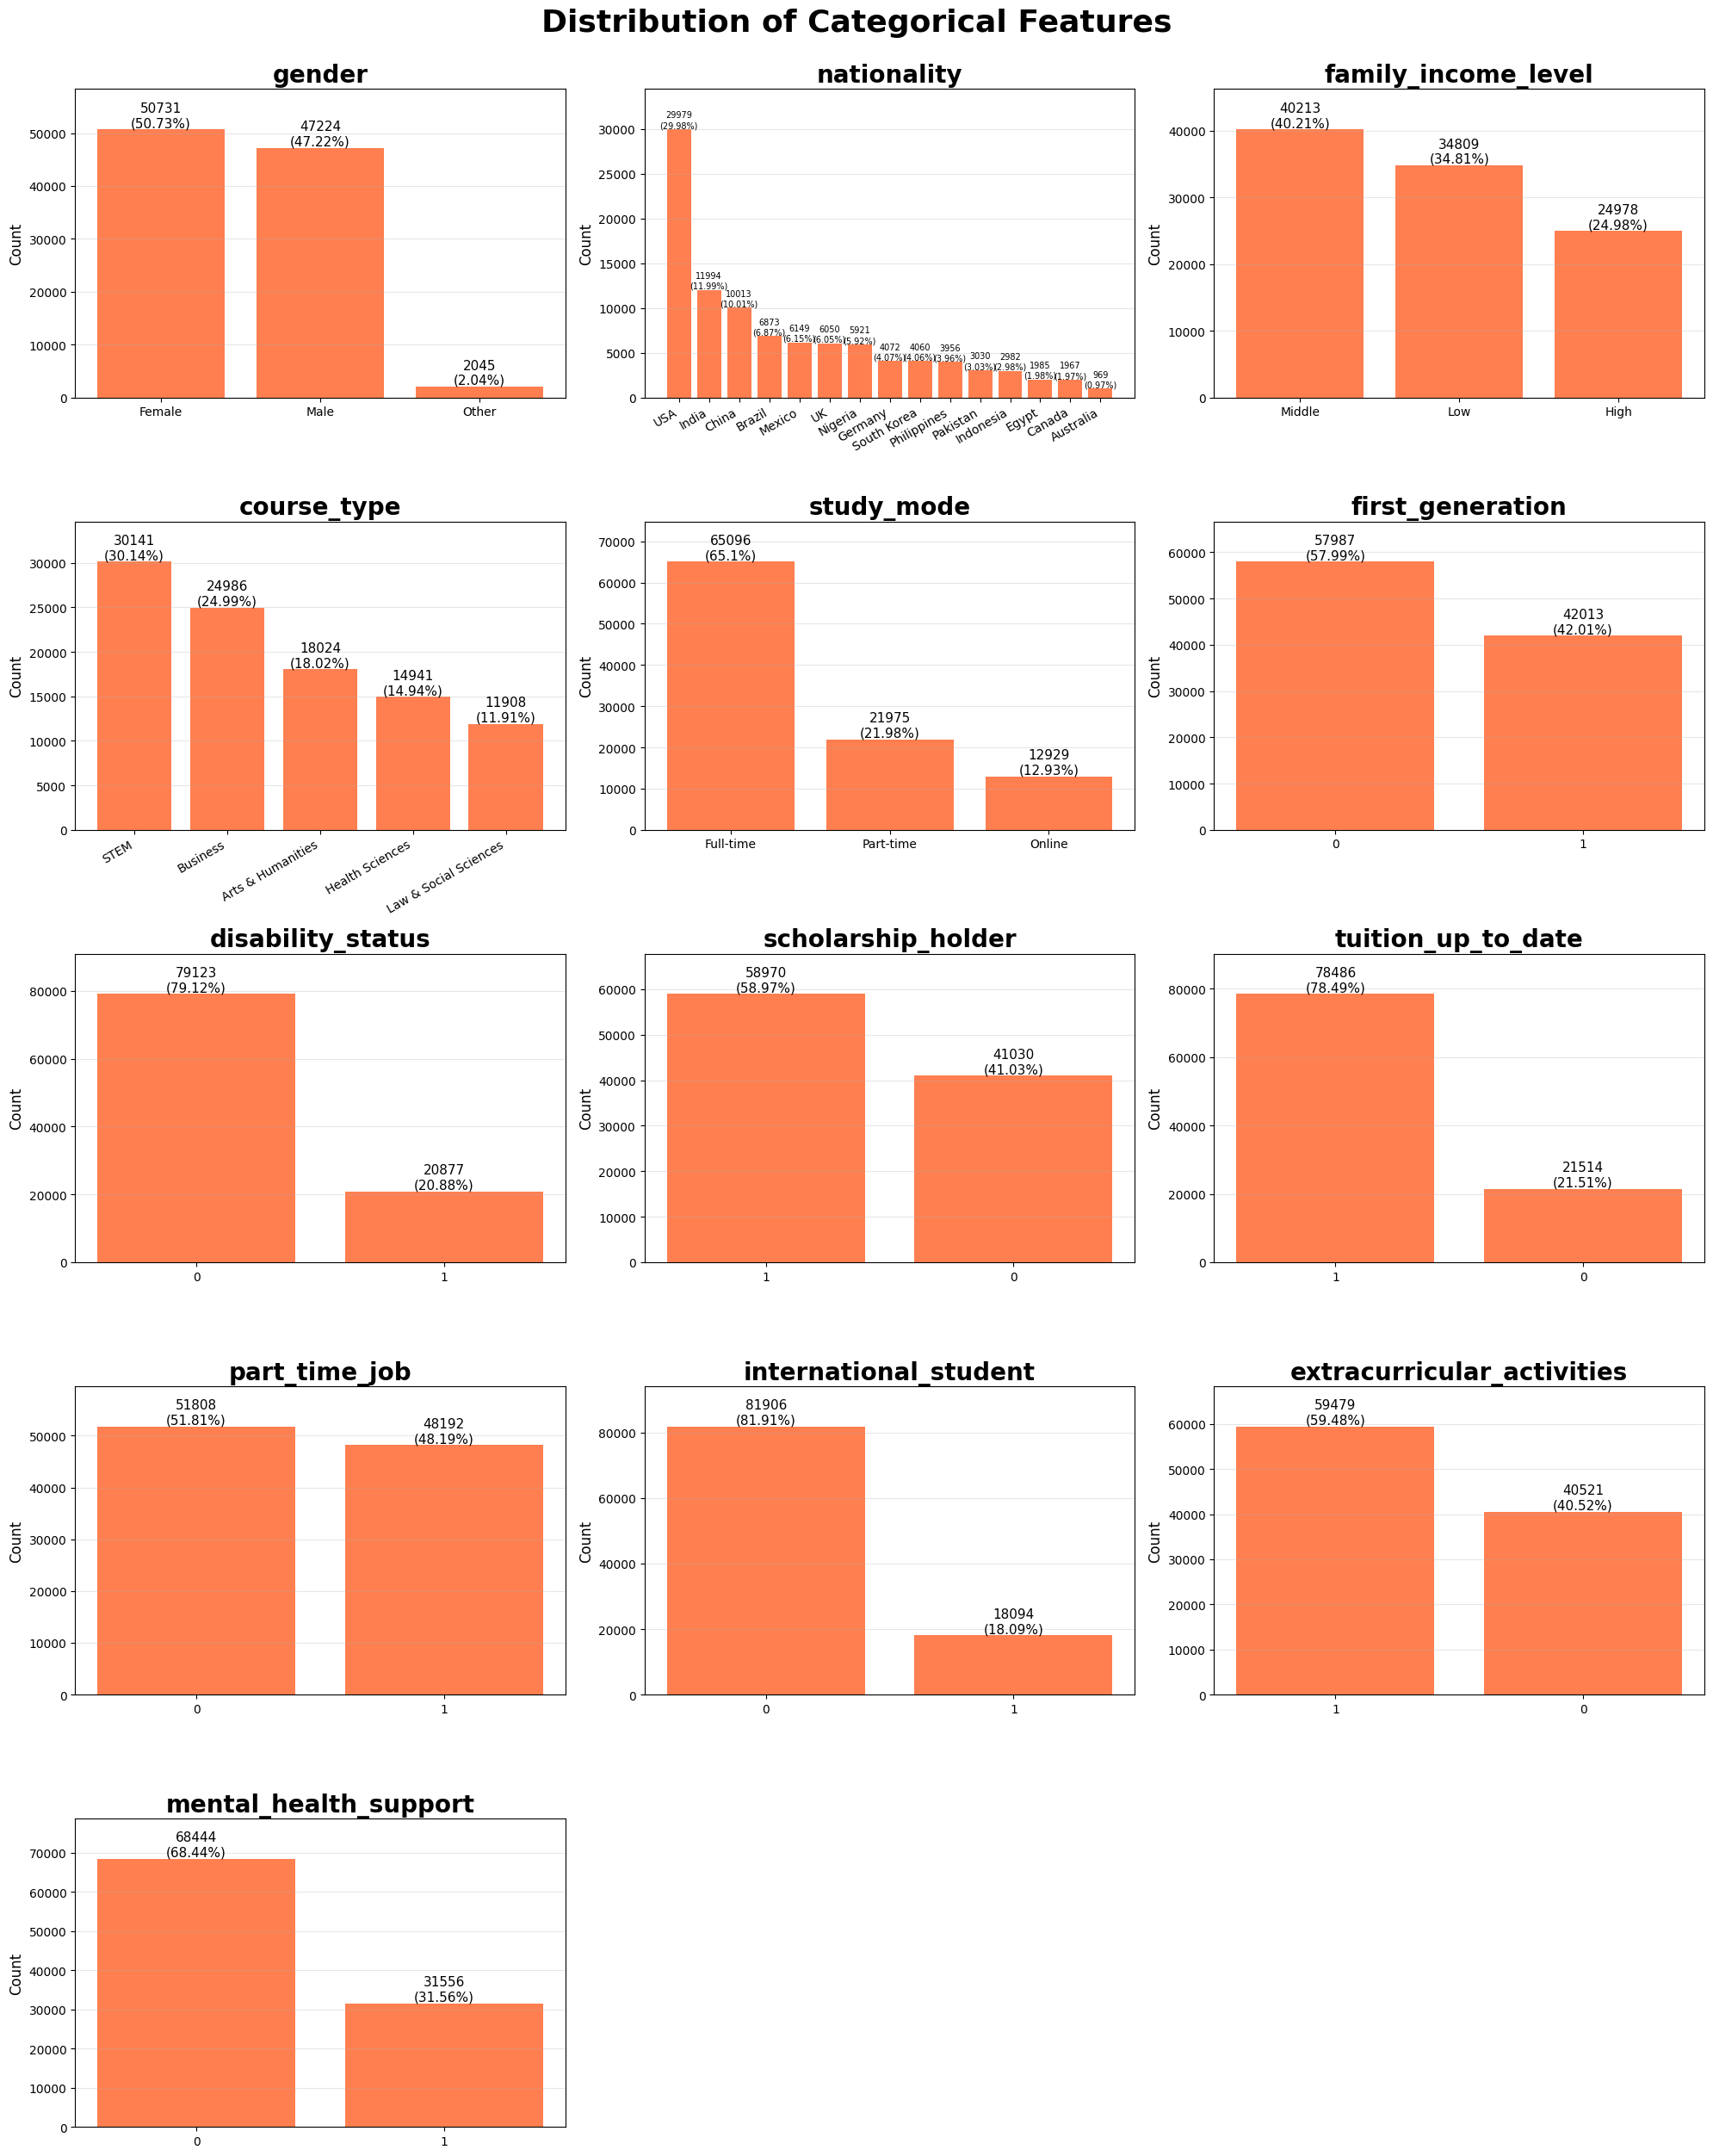

In [12]:
def plot_categorical_distributions(df, columns, title=''):
    """
    Строит распределения категориальных признаков с помощью столбчатых диаграмм (barplot)

    Параметры:
    df : pandas.DataFrame
        датафрейм, содержащий категориальные признаки для анализа

    columns : list
        список названий категориальных (в том числе бинарных) признаков,
        для которых необходимо построить распределения

    title : str, по умолчанию ''
        общий заголовок для всех построенных графиков

    Что рассчитывается:
    для каждого категориального признака рассчитываются:
        - количество наблюдений в каждой категории (Count);
        - доля каждой категории от общего числа наблюдений в процентах (Percent)

    Что строится:
    для каждого признака строится:
        - столбчатая диаграмма, где высота столбца - количество наблюдений в категории
        - подпись над каждым столбцом: количество и процент
        - горизонтальная сетка по оси Y для удобства сравнения высот
    Графики располагаются по 3 в строке, пустые ячейки сетки удаляются.
    Если категорий больше 6 (nationality) или названия длинные (course_type), подписи по оси X поворачиваются"""

    # кол-во признаков
    n_cols = len(columns)

    # максимум 3 графика в одной строке
    n_rows = (n_cols + 2) // 3

    # создаем сетку графиков
    fig, ax = plt.subplots(n_rows, 3, figsize=(20, 5 * n_rows))

    # преобразуем axes в одномерный массив
    ax = np.atleast_1d(ax).flatten()

    # строим график для каждого признака
    for i, col in enumerate(columns):

        # количество значений каждой категории
        counts = df[col].value_counts(dropna=False)

        # процент каждой категории
        percents = (df[col].value_counts(normalize=True, dropna=False).mul(100).round(2))

        # позиции столбцов по оси X
        x = np.arange(len(counts))

        # много категорий или длинные названия - поворачиваем подписи
        many = len(counts) > 6
        rotate = many or counts.index.astype(str).str.len().max() > 12

        # строим barplot через matplotlib
        ax[i].bar(x, counts.values, color='coral')

        # добавляем запас сверху, чтобы подписи count и percent не выходили за график
        ax[i].set_ylim(0, counts.max() * 1.15)

        # заголовок графика
        ax[i].set_title(f'{col}', fontsize=20, fontweight='bold')

        # подпись оси Y
        ax[i].set_ylabel('Count', fontsize=12)

        # названия категорий по оси X
        ax[i].set_xticks(x)
        ax[i].set_xticklabels(counts.index.astype(str), rotation=30 if rotate else 0, ha='right' if rotate else 'center')

        # Сетка
        ax[i].grid(axis='y', alpha=0.3)

        # добавляем count и percent над каждым столбцом
        for j, (count, percent) in enumerate(zip(counts.values, percents.values)):
            ax[i].text(j, count, f'{count}\n({percent}%)', ha='center', va='bottom', fontsize=7 if many else 11)

    # удаляем пустые графики
    for j in range(len(columns), len(ax)):
        fig.delaxes(ax[j])

    # общий заголовок
    plt.suptitle(title, fontsize=26, fontweight='bold', y=1.00)

    plt.tight_layout()
    plt.show()


categorical_for_eda = cat + binary

plot_categorical_distributions(df_, categorical_for_eda, title='Distribution of Categorical Features')

<font size="4">

Анализ распределений категориальных признаков

- `gender`: Female 50.73%, Male 47.22%, Other всего 2.04% (2045 студентов) - группа маленькая, но для 100000 строк оценки по ней ещё устойчивы
- `nationality`: 15 стран, USA 29.98%, India 11.99%, China 10.01%, самая маленькая - Australia 0.97% (969). При One-Hot кодировании получится 15 столбцов
- `family_income_level`: Middle 40.21%, Low 34.81%, High 24.98%. Это порядковый признак (Low < Middle < High)
- `course_type`: STEM 30.14%, Business 24.99%, Arts & Humanities 18.02%, Health Sciences 14.94%, Law & Social Sciences 11.91%
- `study_mode`: Full-time 65.10%, Part-time 21.98%, Online 12.93%
- Бинарные: `first_generation` 42.0%, `disability_status` 20.9%, `scholarship_holder` 59.0%, `tuition_up_to_date` 78.5%, `part_time_job` 48.2%, `international_student` 18.1%, `extracurricular_activities` 59.5%, `mental_health_support` 31.6%. Доли совпадают с заявленными в описании датасета

Сильно редких категорий нет (минимум ~1%), объединять их не обязательно

</font>

### Распределения числовых признаков по таргет классу

<font size="4">

Строим не для всех 19 признаков, а для 6, где важна именно форма различий, а не только ее направление (направление и силу связи для всех признаков покажет следующий график с логитами):

- `gpa_semester_1`, `gpa_semester_2` - по описанию датасета и по логике отчисления это главные признаки; важно увидеть, насколько сильно перекрываются классы даже у лучшего признака - это верхняя планка для one-feature model
- `units_failed` - несданные дисциплины - прямая формальная причина отчисления; дискретный признак, смотрим, с какого числа несданных начинают преобладать отчисленные
- `attendance_rate` - главный признак вовлеченности; у него «нагромождение» на 100%, интересно, кто в нем - отчисленные или нет
- `missed_deadlines` - много нулей; смотрим, как нули распределены между классами
- `weekly_work_hours` - смесь «не работает» и «работает 5-40 часов»; смотрим, отличаются ли классы долей неработающих или числом часов

</font>

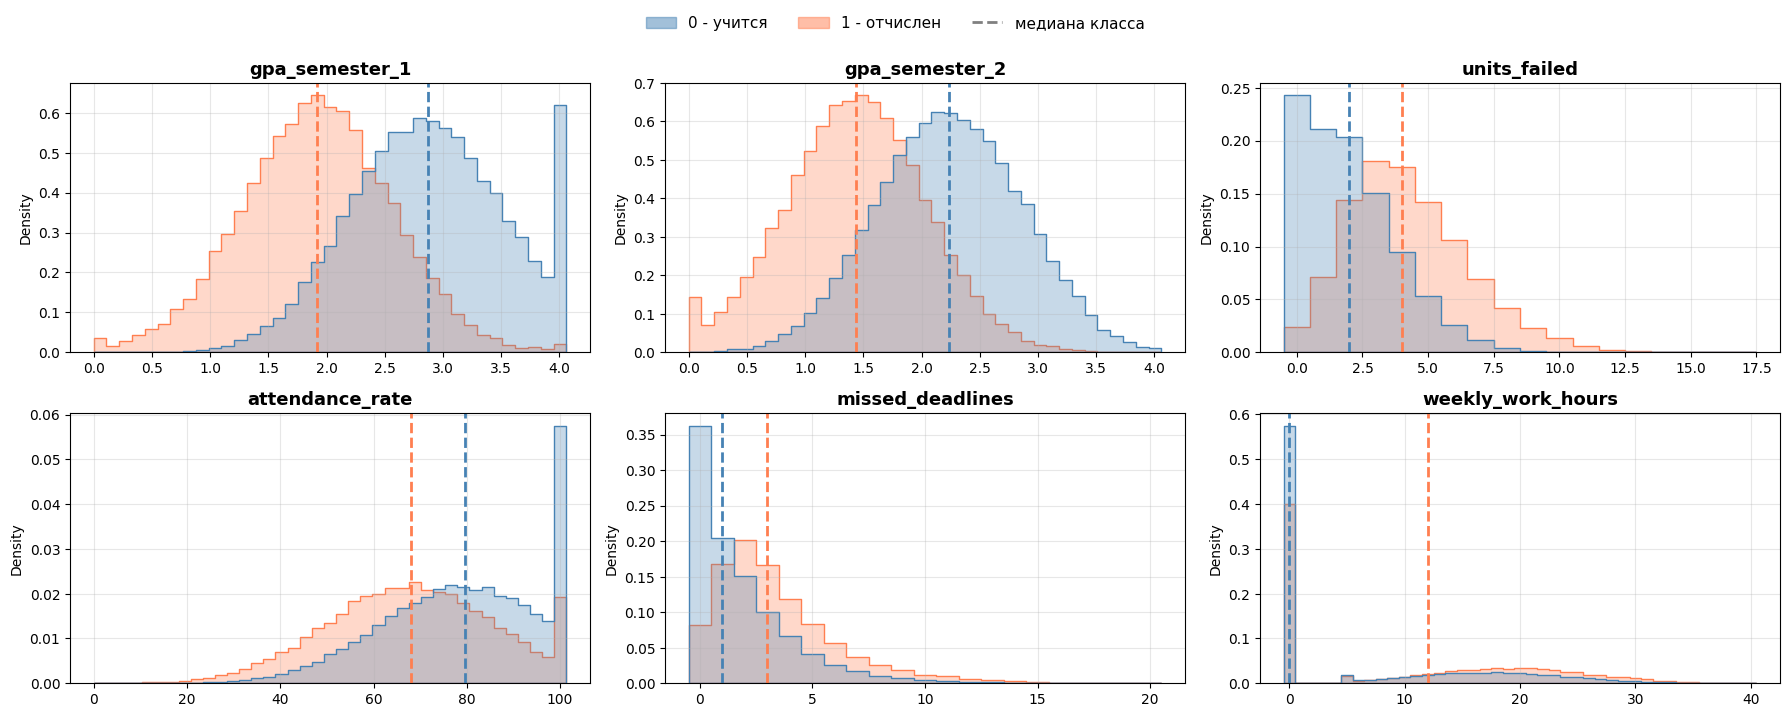

In [13]:
def plot_numeric_by_target(df, columns, target='dropout', n_cols=3, max_discrete=40, labels=(), colors=('steelblue', 'coral')):
    """
    Строит распределения числовых признаков отдельно для каждого класса бинарного таргета

    Параметры:
    df : pandas.DataFrame
        датафрейм с признаками и таргетом
    columns : list
        числовые признаки
    target : str, по умолчанию 'dropout'
        бинарный таргет 0/1
    n_cols : int, по умолчанию 3
        количество графиков в одной строке
    max_discrete : int, по умолчанию 40
        признак с таким или меньшим числом уникальных значений рисуется по значениям (discrete=True),
        у остальных ~40 бинов, ширина бина кратна шагу значений признака
    labels, colors : tuple
        подписи и цвета классов 0 и 1

    Что строится:
    для каждого признака - две гистограммы плотности (stat='density', common_norm=False):
    каждая нормирована на свой класс, поэтому формы сравнимы при дисбалансе.
    Вертикальные линии - медианы признака в каждом классе
    """
    n_rows = (len(columns) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.6 * n_rows))
    axes = np.atleast_1d(axes).flatten()

    # подписи классов вместо 0/1, чтобы палитра однозначно сопоставлялась с классом
    data = df[columns + [target]].copy()
    data['class'] = data[target].map({0: labels[0], 1: labels[1]})
    palette = {labels[0]: colors[0], labels[1]: colors[1]}

    for ax, col in zip(axes, columns):
        is_discrete = df[col].nunique() <= max_discrete

        if is_discrete:
            bins = 'auto'
        else:
            # бины кратны шагу значений (у sleep_hours шаг 0.1), иначе на гистограмме появляются ложные «полосы»
            values = np.sort(df[col].unique())
            step = np.diff(values).min()
            width = step * np.ceil((values[-1] - values[0]) / step / 40)
            bins = np.arange(values[0] - step / 2, values[-1] + width, width)

        sns.histplot(data=data, x=col, hue='class', hue_order=list(labels), palette=palette,
                     stat='density', common_norm=False, element='step', fill=True, alpha=0.3,
                     discrete=is_discrete, bins=bins, legend=False, ax=ax)

        # медианы в каждом классе
        for cls, color in zip((0, 1), colors):
            ax.axvline(df.loc[df[target] == cls, col].median(), color=color, linestyle='--', linewidth=2)

        ax.set_title(col, fontsize=13, fontweight='bold')
        ax.set_xlabel('')
        ax.grid(alpha=0.3)

    for ax in axes[len(columns):]:
        fig.delaxes(ax)

    # одна общая легенда для всех графиков
    handles = [Patch(color=c, alpha=0.5, label=l) for l, c in zip(labels, colors)]
    handles += [Line2D([], [], color='gray', linestyle='--', lw=2, label='медиана класса')]
    fig.legend(handles=handles, loc='upper center', ncol=len(handles), fontsize=11, frameon=False,
               bbox_to_anchor=(0.5, 1.0))
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

chunk_features = ['gpa_semester_1', 'gpa_semester_2', 'units_failed', 'attendance_rate', 'missed_deadlines', 'weekly_work_hours']

plot_numeric_by_target(df_, chunk_features, labels=('0 - учится', '1 - отчислен'))

<font size="4">

Медианы у неотчисленных (0) и отчисленных (1):

- `gpa_semester_1`: 2.87 против 1.92 - распределения сдвинуты почти на 1 балл, перекрытие наименьшее из всех признаков. `gpa_semester_2`: 2.24 против 1.44. Но даже здесь в середине (GPA около 2-2.5) есть и те, и другие - одним признаком классы идеально не разделить
- `units_failed`: 2 против 4. До 2 несданных преобладают неотчисленные, с 4-5 несданных - отчисленные
- `attendance_rate`: 79.7 против 68.1. «Нагромождение» на 100% почти целиком у неотчисленных
- `missed_deadlines`: 1 против 3. Ноль пропущенных дедлайнов - в основном у неотчисленных, у отчисленных пик сдвинут на 1-3
- `weekly_work_hours`: 0 против 12. Классы отличаются в первую очередь долей неработающих: больше половины неотчисленных не работают, а среди отчисленных больше работающих. Среди работающих распределение часов у отчисленных сдвинуто вправо

Вывод: у GPA и `units_failed` классы различаются сдвигом всего распределения, у `missed_deadlines` и `weekly_work_hours` - в первую очередь долей нулей. Для второй пары важно проверить, достаточно ли линейного признака или нужен отдельный индикатор «> 0» (следующий график)

</font>

### Модель до модели

<font size="4">
    
По сути это логистическая регрессия без обучения на одном признаке (будет и на двух): вместо того чтобы подбирать коэффициенты, считаем по данным напрямую ту величину, которую модель описывает прямой, - логит доли отчисленных в каждом бине признака. Пунктирная прямая через эти точки - почти то, что получила бы логистическая регрессия.

<font/>

<font size="4">
    
#### Логит отчисления по числовым признакам

Поскольку логистическая регрессия не предсказывает вероятность отчисления напрямую, графики будем строить не по доле отчисленных. А по тому числу, которое модель считает на самом деле: сначала она складывает вклады признаков в `z = b0 + b1*x1 + ... + bk*xk`, и только потом через сигмоиду переводит его в вероятность. Это `z` и есть логит, то есть логарифм шанса: `logit(p) = ln(p / (1 - p))`, где шанс показывает, во сколько раз отчисленных больше, чем оставшихся.

Логит растягивает долю из [0, 1] на всю числовую прямую: p = 0.5 даёт 0, p = 0.27 даёт -1, p = 0.12 даёт -2, p = 0.05 даёт -3. Разница логитов в 1 значит, что шансы отличаются примерно в 2.7 раза, в 2 - примерно в 7.4 раза.

Отсюда главное допущение модели: каждый признак двигает логит на одну и ту же величину на единицу признака, в любой точке его шкалы. То есть модель считает, что логит от признака зависит линейно. Нормальность признаков ей не нужна, а вот это нужно. Если в данных логит идёт по кривой (скачок в нуле, насыщение, U-форма), модель всё равно проведёт прямую и будет ошибаться на краях.

Это касается только линейных моделей. Деревья и бустинг режут признак порогами, сами ловят кривую, а монотонные преобразования на них не влияют. Поэтому преобразования по этим графикам делаем только в пайплайне линейных моделей, а в деревья подаём исходные признаки.

**Зачем нужен график**

1. Понять, в каком виде подавать признак в линейную модель. Точки лежат на пунктире в пределах усов - оставляем как есть (после StandardScaler). Точки уходят от пунктира (изгиб, ступенька, плато) - подбираем преобразование по форме: индикатор «> 0», квадрат или сплайн.

2. Заранее прикинуть, какие признаки вообще что-то дают. Общая доля отчисленных около 0.32, это логит примерно -0.75. Если линия лежит горизонтально около этого уровня, признак сам по себе с отчислением не связан. Чем больше перепад логита от левого края до правого, тем сильнее признак. Это потом пригодится, чтобы сверить с важностями признаков в обученных моделях: если модель считает важным признак с плоским графиком, надо разбираться почему.

3. Понимать коэффициенты и ограничения моделей. Наклон пунктира примерно равен коэффициенту признака в логистической регрессии, если бы признак был в модели один, а экспонента от наклона показывает, во сколько раз меняются шансы на единицу признака. Для бустинга по монотонности графика видно, где можно задать ограничение на монотонность (например, «чем выше GPA, тем ниже риск»).

</font>

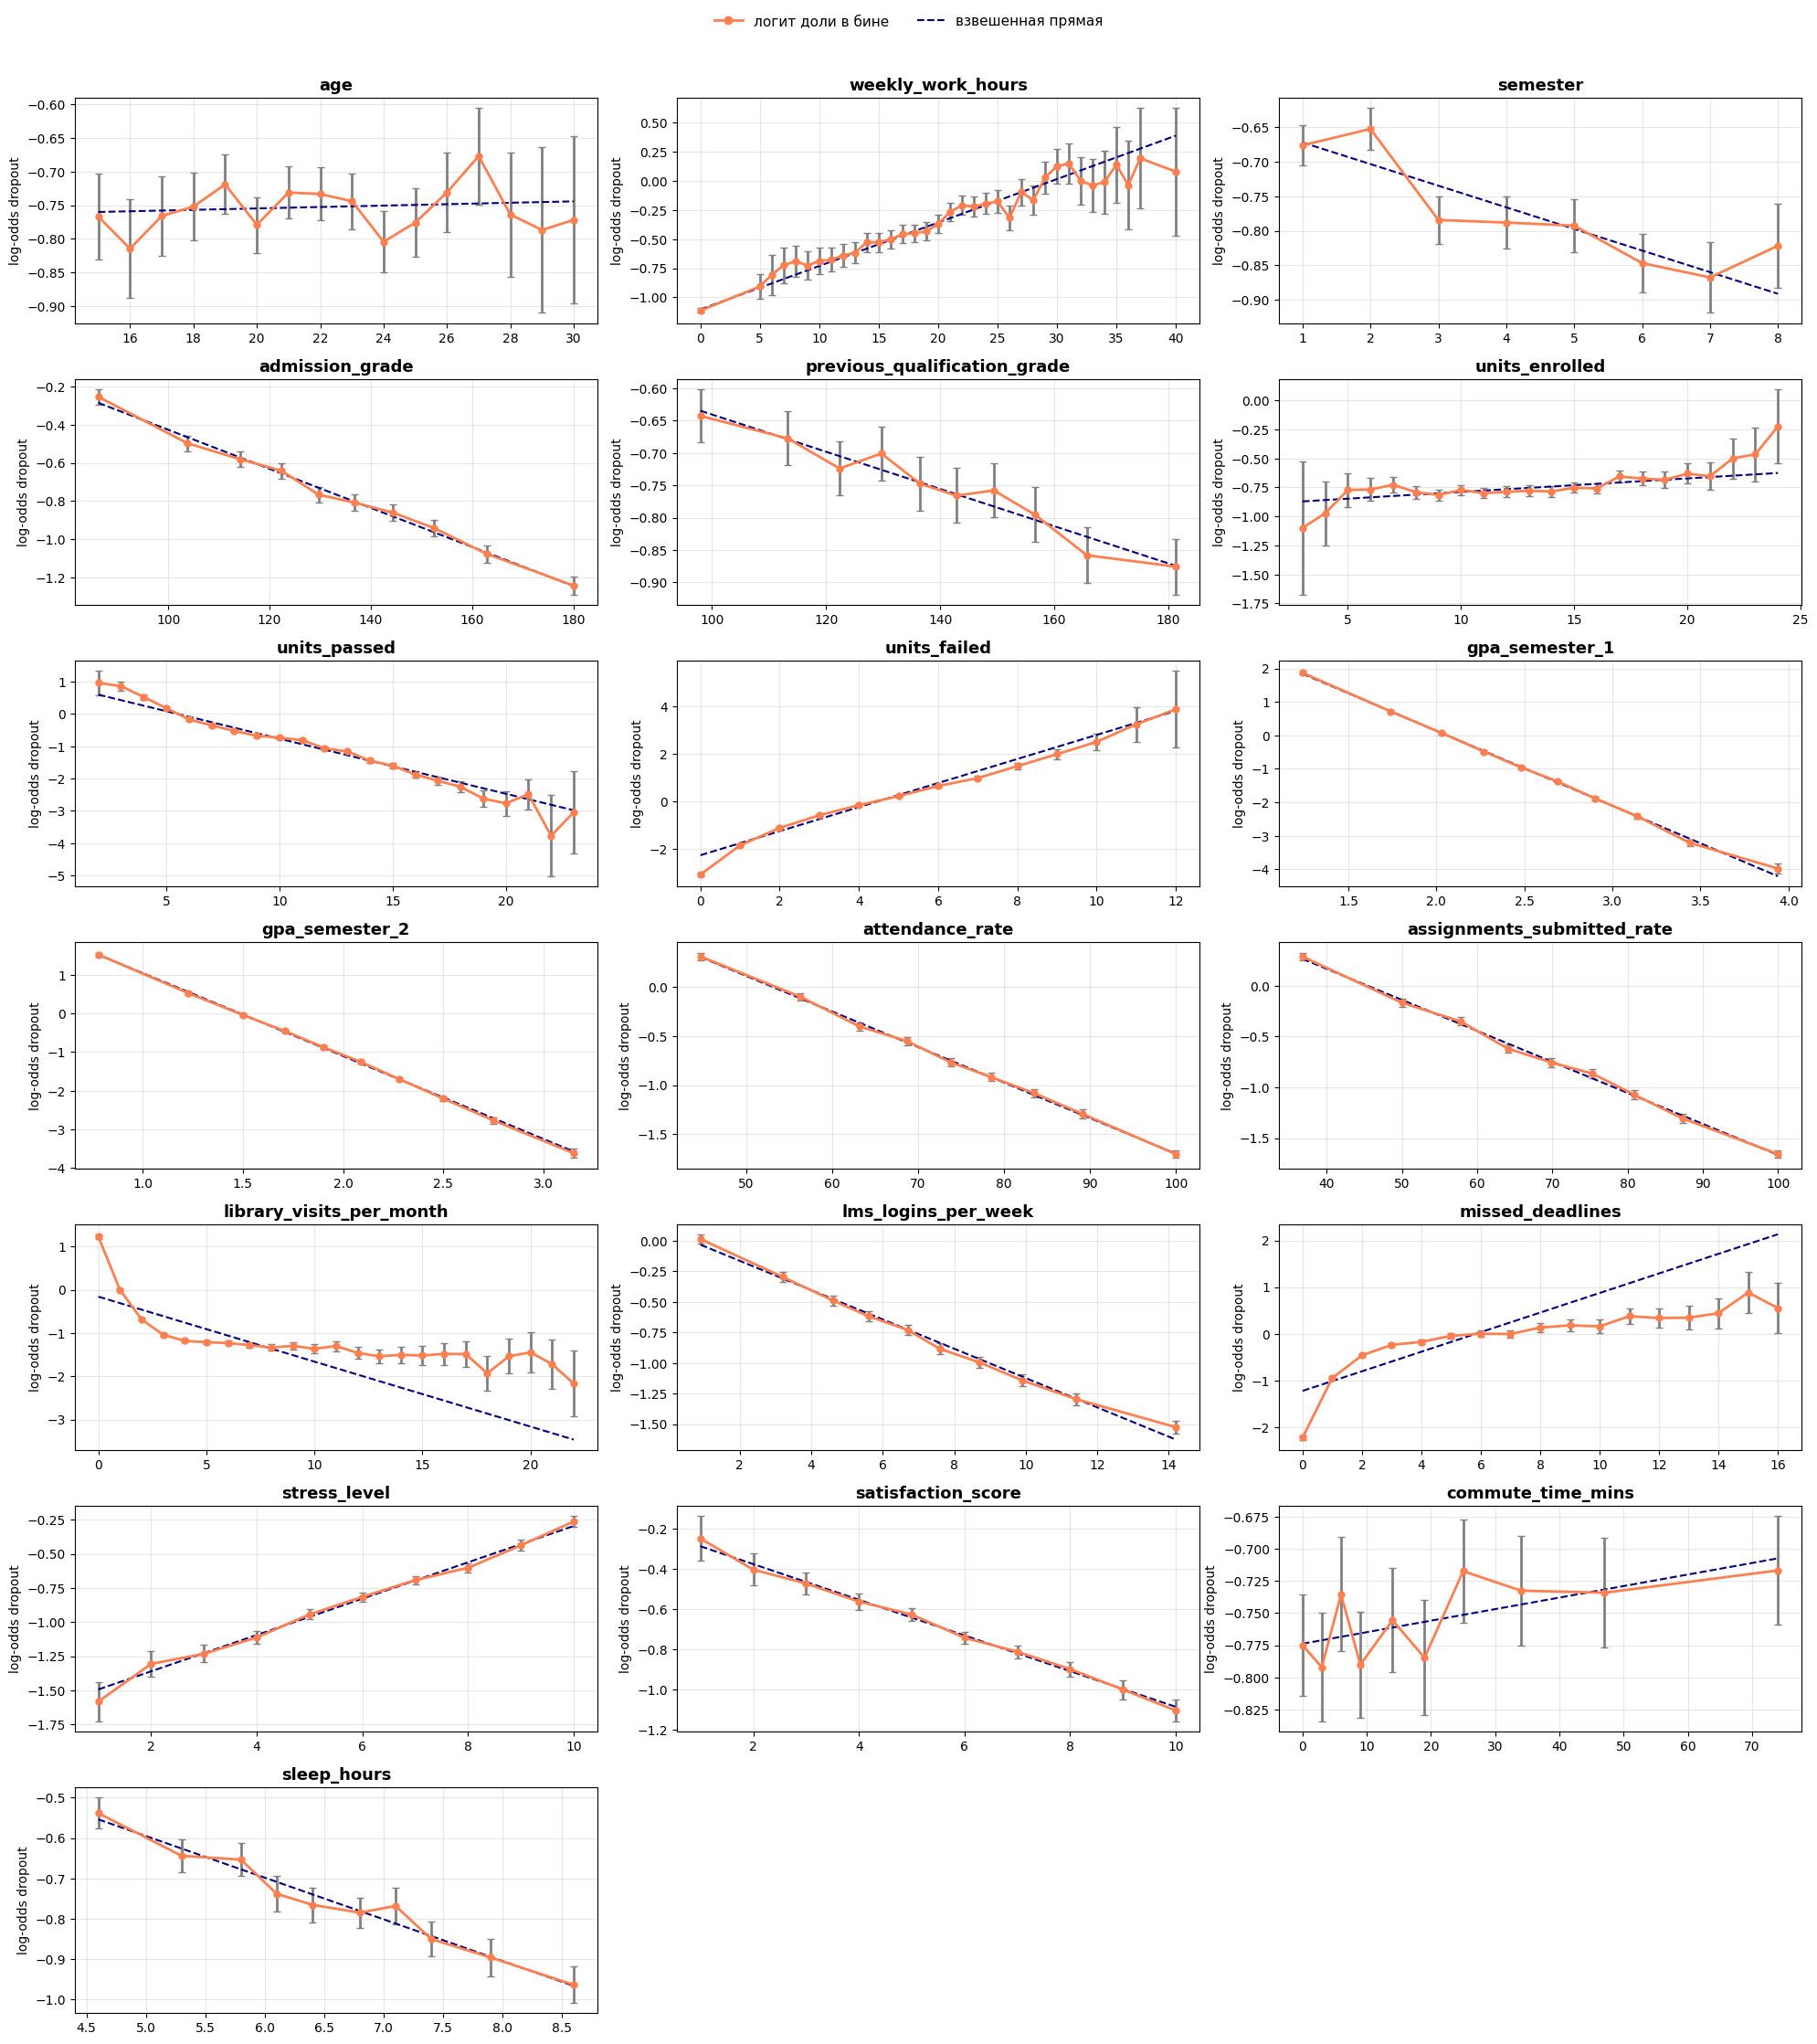

In [14]:
def plot_logit_vs_numeric(df, columns, target='dropout', n_cols=3, n_bins=10, max_discrete=40, min_count=50):
    """
    Строит эмпирический логит доли положительного класса по бинам числовых признаков

    Параметры:
    df : pandas.DataFrame
        датафрейм с признаками и таргетом
    columns : list
        числовые признаки
    target : str, по умолчанию 'dropout'
        бинарный таргет 0/1
    n_cols : int, по умолчанию 3
        количество графиков в одной строке
    n_bins : int, по умолчанию 10
        число квантильных бинов для непрерывных признаков
    max_discrete : int, по умолчанию 40
        признак с таким или меньшим числом уникальных значений группируется по значениям
    min_count : int, по умолчанию 50
        бины, где меньше min_count объектов, не рисуются: логит по ним слишком шумный

    Что рассчитывается:
    для каждого бина: доля target = 1, логит log((k + 0.5) / (n - k + 0.5)), где k - число единиц, n - размер бина
    (+0.5 - поправка, чтобы логит не уходил в бесконечность при доле 0 или 1),
    стандартная ошибка логита sqrt(1 / (k + 0.5) + 1 / (n - k + 0.5))

    Что строится:
    точки логита с 95% интервалами, линия через точки и взвешенная (по 1 / SE) прямая,
    по оси X - медиана признака в бине (или само значение для дискретных)
    """
    # считаем, сколько строк нужно, чтобы уместить все графики по n_cols в ряд
    n_rows = (len(columns) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 3.2 * n_rows))
    
    # приводим оси к плоскому одномерному массиву, чтобы перебирать их одним циклом
    # независимо от того, одна строка графиков или несколько
    axes = np.atleast_1d(axes).flatten()

    for ax, col in zip(axes, columns):
        # берём только нужный признак и таргет, остальное не нужно
        data = df[[col, target]]

        if data[col].nunique() <= max_discrete:
            # дискретный признак (мало уникальных значений): каждое значение - свой бин,
            # медиана внутри группы равна самому значению
            grouped = data.groupby(col)
            x = grouped[col].median().values
        else:
            # непрерывный признак: режем на квантильные бины примерно одинакового размера,
            # duplicates='drop' убирает совпадающие границы (бывает при большом числе одинаковых значений)
            bins = pd.qcut(data[col], q=n_bins, duplicates='drop')
            # observed=True - группируем только по реально встречающимся интервалам
            grouped = data.groupby(bins, observed=True)
            # по оси X ставим медиану признака в бине, она устойчивее к выбросам, чем середина интервала
            x = grouped[col].median().values

        # k - число отчисленных (единиц таргета) в бине, n - размер бина
        k = grouped[target].sum().values
        n = grouped[target].size().values

        # выкидываем маленькие бины: при малом n логит слишком шумный
        keep = n >= min_count
        x, k, n = x[keep], k[keep], n[keep]

        # эмпирический логит с поправкой +0.5, чтобы не получить log(0) при доле 0 или 1
        logit = np.log((k + 0.5) / (n - k + 0.5))
        # стандартная ошибка логита: растёт, когда бин маленький или доля близка к 0 или 1
        se = np.sqrt(1 / (k + 0.5) + 1 / (n - k + 0.5))

        # точки логита по бинам, соединённые линией, с усами +-1.96 se (95% интервал)
        ax.errorbar(x, logit, yerr=1.96 * se, fmt='o-', color='coral', ecolor='gray',
                    capsize=3, markersize=5, linewidth=2, label='логит доли в бине')

        # взвешенная прямая: точные бины весят больше
        # веса 1 / se, потому что polyfit умножает на вес остаток, а не его квадрат
        # (в квадратах это даёт стандартные веса 1 / se^2)
        # это то, как признак "увидит" логистическая регрессия, если подать его как есть
        slope, intercept = np.polyfit(x, logit, deg=1, w=1 / se)
        # рисуем прямую только в пределах наблюдаемых значений признака
        xs = np.linspace(x.min(), x.max(), 100)
        ax.plot(xs, slope * xs + intercept, '--', color='navy', linewidth=1.5, label='прямая')

        # оформление: название признака сверху, по оси Y логарифм шансов отчисления
        ax.set_title(col, fontsize=13, fontweight='bold')
        ax.set_xlabel('')
        ax.set_ylabel('log-odds dropout')
        ax.grid(alpha=0.3)

    # удаляем лишние пустые оси, если признаков меньше, чем ячеек в сетке
    for ax in axes[len(columns):]:
        fig.delaxes(ax)

    # одна общая легенда сверху вместо легенды на каждом графике,
    # элементы задаём вручную через Line2D, чтобы не тащить их из конкретной оси
    handles = [Line2D([], [], color='coral', marker='o', lw=2, label='логит доли в бине'),
               Line2D([], [], color='navy', linestyle='--', lw=1.5, label='взвешенная прямая')]
    fig.legend(handles=handles, loc='upper center', ncol=2, fontsize=11, frameon=False, bbox_to_anchor=(0.5, 1.0))
    # rect оставляет сверху место под общую легенду, чтобы она не наезжала на графики
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

# строим графики для всех числовых признаков, по 3 в ряд
plot_logit_vs_numeric(df_, num, n_cols=3)

<font size="4">

Вывод по графикам логитов

**Линейность**

- Для 16 из 19 признаков логит меняется по прямой или почти не меняется. Логистическая регрессия опишет их без преобразований - для линейной модели это хорошие условия. Такая ровность, скорее всего, особенность синтетических данных: похоже, генератор задавал логит линейной формулой
- Изгиб есть у двух признаков - `missed_deadlines` и `library_visits_per_month`. У обоих главное - переход «0 -> не 0», дальше эффект насыщается. Если подать их как есть, прямая занизит риск в нуле и завысит его на хвосте (у `missed_deadlines` при 15 пропусках прямая дает ~+2, а на деле ~+0.5)
- У `units_failed` первый шаг (0 -> 1 несданная) крупнее остальных, а у `semester` - слабая ступенька после 2-го семестра. Оба отклонения небольшие, на качество почти не повлияют

**Сила признаков** (перепад логита по диапазону признака)

- Сильнее всего с отчислением связана успеваемость: GPA (~ 5-6), `units_failed` (~ 7) и `units_passed` (~ 4). У units перепад частично завышен крайними бинами, где студентов мало
- Дальше идут `missed_deadlines` и `library_visits_per_month` (~ 2.7, но нелинейно), посещаемость и сданные задания (~ 2), LMS (~ 1.5), стресс и часы работы (~ 1.3), вступительный балл и удовлетворенность (~ 1)
- Слабая связь (перепад меньше 0.5) - у `sleep_hours`, `previous_qualification_grade`, `semester`. Связи нет у `age`, `commute_time_mins` и `units_enrolled` (сам по себе)

В итоге есть часть ответов на вопросы исследования

- По графику важнее сам факт пропуска дедлайнов. Первый пропуск поднимает долю отчисленных с 10% до 28% (шансы x3.5), а каждый следующий добавляет к логиту всего ~0.1. Окончательно проверим на модели - по весу `missed_deadlines` в полной модели
- `gpa_semester_1` разделяет классы не хуже `gpa_semester_2` (перепад ~6 против ~5). Значит, модель без данных второго семестра, вероятно, потеряет немного
- Подработка: точка «0 часов» лежит на той же прямой, что и работающие студенты, скачка нет. Риск растет с каждым часом, поэтому `part_time_job` сверх `weekly_work_hours` ничего не добавляет - его можно не подавать в модель

Полуучаем что:
- Признаки с прямым логитом подаем как есть, после StandardScaler
- `missed_deadlines` и `library_visits_per_month` тоже подаем как есть: изгиб на графике одного признака может объясняться другими признаками, это проверим по весам полной модели. Сплайны и PolynomialFeatures не нужны
- Из тройки `units_enrolled`, `units_passed`, `units_failed` оставляем два признака (`units_failed` и `units_enrolled`), иначе из-за тождества коэффициенты не определены
- `age`, `commute_time_mins`, `units_enrolled` и признаки со слабой связью - кандидаты на удаление или обнуление L1-регуляризацией. Совсем не удаляем до модели: график одномерный, и у признака могут найтись взаимодействия с другими
- Наклоны на графиках - это эффекты признаков по отдельности. В модели коэффициенты коррелирующих признаков (GPA и units, посещаемость, задания и LMS) будут меньше, потому что признаки делят общий сигнал

</font>

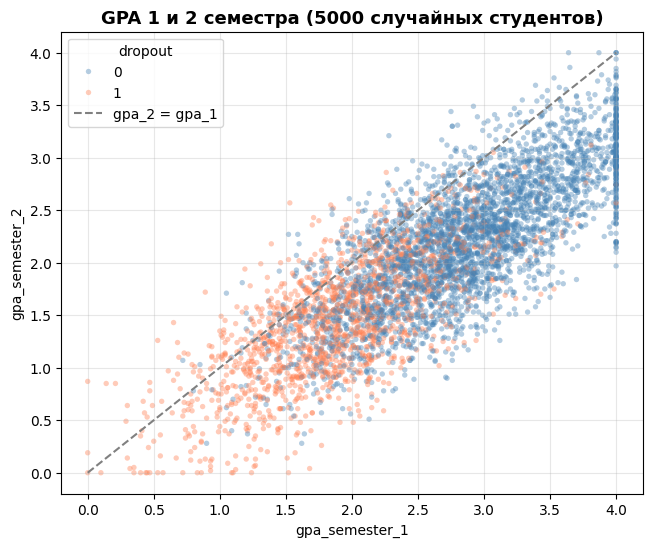

gpa2,"[0.0, 1.5)","[1.5, 2.0)","[2.0, 2.5)","[2.5, 4.01)"
gpa1,,,,
"[0.0, 2.0)",0.793,0.607,0.529,0.451
"[2.0, 2.5)",0.488,0.394,0.302,0.212
"[2.5, 3.0)",0.321,0.231,0.162,0.108
"[3.0, 4.01)",0.155,0.112,0.066,0.032


In [15]:
#Каждая точка - студент: по оси X его GPA за первый семестр, по оси Y - за второй. 
#Синие - учатся, оранжевые - отчислены. Серая диагональ - «GPA не изменился». 
#Это единственный график, где два самых сильных признака показаны вместе, а не по отдельности. 
#100000 точек слились бы в сплошное пятно, поэтому берем случайную выборку 5000 точек

gpa_bins = pd.cut(df_['gpa_semester_1'], bins=[0, 2, 2.5, 3, 4.01], right=False)

# первый и второй семестр: даёт ли GPA 2 семестра информацию сверх GPA 1
sample = df_.sample(5000, random_state=42)

plt.figure(figsize=(7.5, 6))
sns.scatterplot(data=sample, x='gpa_semester_1', y='gpa_semester_2', hue='dropout',
                palette={0: 'steelblue', 1: 'coral'}, alpha=0.4, s=15, linewidth=0)
plt.plot([0, 4], [0, 4], '--', color='gray', label='gpa_2 = gpa_1')
plt.title('GPA 1 и 2 семестра (5000 случайных студентов)', fontsize=13, fontweight='bold')
plt.legend(title='dropout')
plt.grid(alpha=0.3)
plt.show()

gpa2_bins = pd.cut(df_['gpa_semester_2'], bins=[0, 1.5, 2, 2.5, 4.01], right=False)
(df_.assign(gpa1=gpa_bins, gpa2=gpa2_bins)
    .pivot_table(index='gpa1', columns='gpa2', values='dropout', aggfunc='mean', observed=True)
    .round(3))

<font size="4">

- Отчисленные собраны в левом нижнем углу, синие - в правом верхнем, а между ними - размытая наклонная полоса без изгибов и «островов». Логистическая регрессия разделяет классы как раз прямой линией (в этих осях ее граница - прямая `w1 * gpa1 + w2 * gpa2 = const`), поэтому такая картина ей подходит. Если бы отчисленные образовывали кольцо или два отдельных облака, понадобились бы дополнительные признаки
- Полоса наклонная, а не вертикальная: при одном и том же GPA 1 студенты с низким GPA 2 чаще оранжевые. Значит, второй семестр добавляет информацию сверх первого - это проверяем таблицей ниже
- Почти все точки ниже диагонали: во втором семестре оценки у всех ниже (то самое -0.59 в среднем). Вертикальная «стена» точек при GPA 1 = 4.0 - обрезка значений сверху

Таблица под графиком - доля отчисленных среди всех 100000 студентов: строки - группы по GPA первого семестра, столбцы - по GPA второго. Например, 0.793 в левом верхнем углу: из студентов с GPA 1 < 2 и GPA 2 < 1.5 отчислено 79%

Как читать:

- по строке (GPA 1 одинаковый, меняется GPA 2) - видно, что дает второй семестр. У слабых в первом семестре (GPA 1 < 2) доля падает с 79% до 45%, если во втором семестре GPA 2.5+. У сильных (GPA 1 3+) - с 16% до 3%
- по столбцу (GPA 2 одинаковый, меняется GPA 1) - видно, что дает первый семестр. При GPA 2 < 1.5 доля падает с 79% до 16% по мере роста GPA 1
- в углах таблицы мало студентов (GPA 1 < 2 и GPA 2 2.5+ - всего ~50 человек, GPA 1 3+ и GPA 2 < 1.5 - ~170), поэтому эти доли менее точные

Что это дает:

- оба признака нужны модели: хотя они сильно связаны (корреляция 0.83), каждый сдвигает долю отчисленных при фиксированном другом
- GPA первого семестра в таблице сдвигает долю сильнее, чем второго (по столбцу 79% -> 16%, по строке 79% -> 45%). Для **вопроса 1** это хороший знак: модель раннего предупреждения без GPA 2 потеряет часть качества, но основную информацию дает уже первый семестр

Важный вопрос постановки: GPA второго семестра и число несданных дисциплин известны только к концу года. Для «раннего предупреждения» (найти студента в группе риска как можно раньше) их использовать нельзя. В моделировании сравним полную модель с моделью без «поздних» признаков

<font/>

## Статистический анализ

### Корреляция

In [16]:
cm = sns.color_palette("vlag", as_cmap=True)

corr = df_[num + binary + ['dropout']].corr()

# оставляем только нижний треугольник
mask = np.triu(np.ones(corr.shape, dtype=bool))
corr_lower = corr.mask(mask)
corr_lower = corr_lower.iloc[1:, :-1]

# фильтр: слабые корреляции (|r| < threshold) тоже заменяем на NaN, а то признаков больна многа, и маттрица разрастается и становится нечитаемой
corr_filtered = corr_lower.where(corr_lower.abs() >= 0.20)

# (опционально) убираем строки и столбцы, где не осталось ни одного значения
corr_filtered = corr_filtered.dropna(how='all', axis=0).dropna(how='all', axis=1)

corr_filtered.style \
    .background_gradient(cmap=cm, vmin=-1, vmax=1) \
    .format('{:.2f}', na_rep='') \
    .highlight_null(color='white') \
    .set_properties(**{
        'width': '60px',
        'height': '30px',
        'font-size': '9pt',
        'text-align': 'center'
    })

,weekly_work_hours,units_enrolled,units_passed,units_failed,gpa_semester_1,gpa_semester_2,attendance_rate,assignments_submitted_rate,library_visits_per_month,lms_logins_per_week,missed_deadlines,stress_level
units_passed,,0.83,,,,,,,,,,
units_failed,,0.36,-0.22,,,,,,,,,
gpa_semester_1,,,0.45,-0.75,,,,,,,,
gpa_semester_2,,,0.37,-0.62,0.83,,,,,,,
attendance_rate,,,,,0.26,0.22,,,,,,
assignments_submitted_rate,,,,-0.23,0.32,0.27,0.30,,,,,
library_visits_per_month,,,,-0.23,0.31,0.26,,,,,,
lms_logins_per_week,,,,-0.22,0.24,,,,,,,
missed_deadlines,0.20,,,0.24,-0.32,-0.27,,,,,,
satisfaction_score,,,,,,,,,,,,-0.30


### Мультиколлениарность (VIF)

In [17]:
def calculate_vif(df, num_cols, cat_cols=None):
    """
    Рассчитывает VIF (Variance Inflation Factor) для признаков

    VIF_i = 1 / (1 - R^2_i), где R^2_i - коэффициент детерминации регрессии i-го признака
    на все остальные. Показывает, во сколько раз дисперсия коэффициента при признаке
    больше, чем была бы без мультиколлинеарности. Для логистической регрессии смысл тот же:
    чем выше VIF, тем менее устойчивы и интерпретируемы её коэффициенты

    Параметры:
    df : pandas.DataFrame
        датафрейм с признаками
    num_cols : list
        числовые признаки (таргет сюда не передаем)
    cat_cols : list, по умолчанию None
        категориальные признаки; переводятся в dummy (drop_first=True)

    Возвращает:
    pandas.DataFrame
        признак и его VIF, отсортировано по убыванию VIF

    Интерпретация:
    ~1     - мультиколлинеарности практически нет
    1-5    - обычно приемлемо
    5-10   - заметная мультиколлинеарность
    >10    - сильная мультиколлинеарность
    inf    - признак точно выражается через другие
    """
    data = df[num_cols + (cat_cols or [])].dropna()

    # категориальные признаки переводим в dummy; первую категорию убираем, чтобы dummy не были идеально коллинеарны
    data = pd.get_dummies(data, columns=cat_cols, drop_first=True, dtype=float)

    # variance_inflation_factor не добавляет свободный член сам, без него VIF завышается
    data = add_constant(data)

    # при точной линейной зависимости (units_passed + units_failed = units_enrolled) R^2 = 1 и VIF = 1 / 0.
    # statsmodels об этом предупреждает, и в разных версиях по-разному: RuntimeWarning (деление на ноль),
    # UserWarning (poorly conditioned), SingularMatrixWarning (rank-deficient) - по разу на каждый признак.
    # Предупреждения ожидаемые и разобраны в выводе ниже, поэтому в этом блоке скрываем все
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        vif = pd.DataFrame({
            'feature': data.columns,
            'VIF': [variance_inflation_factor(data.values, i) for i in range(data.shape[1])],
        })

    # VIF для константы не интерпретируется, убираем ее
    vif = vif[vif['feature'] != 'const']

    return vif.sort_values('VIF', ascending=False).reset_index(drop=True)


features_for_vif = num + binary

# units_enrolled сразу исключаем: он точно равен units_passed + units_failed (проверено выше),
# с ним VIF всех трех units_* бесконечный и ничего нового не показывает
features_no_enrolled = [col for col in features_for_vif if col != 'units_enrolled']

# 1) числовые и бинарные признаки
display(calculate_vif(df_, features_no_enrolled).head(10))

# 2) как признаки попадут в модель: + dummy категориальных
display(calculate_vif(df_, features_no_enrolled, cat_cols=cat).head(12))

,feature,VIF
0,gpa_semester_1,5.474690
1,weekly_work_hours,4.763500
2,part_time_job,4.668281
3,gpa_semester_2,3.228517
4,units_failed,2.350791
5,units_passed,1.326595
6,stress_level,1.228751
7,assignments_submitted_rate,1.181862
8,attendance_rate,1.181390
9,satisfaction_score,1.153119


,feature,VIF
0,nationality_USA,22.373019
1,nationality_India,11.778698
2,nationality_China,10.202815
3,nationality_Brazil,7.540020
4,nationality_Mexico,6.896967
5,nationality_UK,6.807983
6,nationality_Nigeria,6.692489
7,gpa_semester_1,5.489713
8,nationality_Germany,4.992181
9,nationality_South Korea,4.981292


<font size="4">

Вывод по мультиколлинеарности

- `units_enrolled` в расчет не берем: из-за тождества `passed + failed = enrolled` VIF у всех трех `units_*` был бы бесконечным (на практике inf или ~1e15 - зависит от погрешности вычислений). Модель без регуляризации не смогла бы однозначно разделить их вклад: одни и те же предсказания дают бесконечно много наборов коэффициентов
- Без `units_enrolled` все нормально: максимум у `gpa_semester_1` (5.47), дальше `weekly_work_hours` (4.76), `part_time_job` (4.67), `gpa_semester_2` (3.23), `units_failed` (2.35). Остальные около 1
- С dummy категориальных признаков VIF у `nationality_USA` 22.4, `nationality_India` 11.8, `nationality_China` 10.2. Это не настоящая мультиколлинеарность, а артефакт кодирования: `drop_first=True` выкинул по алфавиту Australia - самую маленькую страну (0.97%), и сумма остальных 14 dummy почти совпадает с константой. Если взять базовой самую частую страну или оставить все категории с регуляризацией, проблема исчезнет. Для качества предсказаний это не важно, для интерпретации коэффициентов при `nationality` - важно

Вывод: точная зависимость только в тройке `units_*` - одну из трех убираем. Пары `gpa_1` / `gpa_2` и `part_time_job` / `weekly_work_hours` связаны заметно, но допустимо (VIF < 6)

</font>

## Выводы по EDA

<font size="4">

1. **Данные.** 100000 студентов, 33 признака (19 числовых, 8 бинарных, 5 категориальных) + таргет. Пропусков и дубликатов нет. Данные синтетические, и это видно: значения «прилипают» к краям шкал (GPA 4.0, посещаемость 100%, балл 200, возраст 15), возраст не связан с семестром, доля иностранцев одинаковая во всех странах, GPA во втором семестре систематически ниже. Выводы описывают датасет, а не реальных студентов
2. **Таргет.** Отчислено 32%, соотношение ~2.1 : 1. Accuracy неинформативна (Dummy получит 0.68), смотрим recall / precision / F1 по классу 1, ROC-AUC и PR-AUC (у случайной модели 0.32). Разбиение - со `stratify`, threshold подбираем на validation. False Negative (пропущенный студент из группы риска) дороже False Positive
3. **Главное - успеваемость.** Сильнее всего с отчислением связаны GPA первого и второго семестра (перепад логита ~6 и ~5) и число несданных дисциплин. Дальше - вовлеченность (посещаемость, сданные задания, пропущенные дедлайны, библиотека, LMS) и финансы (оплата обучения, подработка, доход семьи). Демография (пол, страна, возраст), направление обучения, статус иностранного студента и время в дороге с отчислением не связаны
4. **Форма зависимостей подходит логистической регрессии.** Для 16 из 19 числовых признаков логит меняется по прямой. Исключения - `missed_deadlines` и `library_visits_per_month`: у них главное - переход «0 -> не 0», дальше эффект насыщается. `weekly_work_hours` линеен от самого нуля, поэтому `part_time_job` сверх часов ничего не дает
5. **Взаимодействий не видно.** Граница между классами в осях GPA 1 x GPA 2 - размытая наклонная полоса, эффект дохода одинаков при любом GPA. Вклады признаков складываются в логите, поэтому PolynomialFeatures, скорее всего, не понадобятся
6. **Мультиколлинеарность.** Точная зависимость `units_passed + units_failed = units_enrolled` - одну из трех убираем. Заметная, но допустимая связь GPA 1 / GPA 2 (r = 0.83) и `part_time_job` / `weekly_work_hours`. Большой VIF у `nationality` - артефакт выбора базовой категории
7. **Выбросы не удаляем.** Невозможных значений нет, выбросы по Тьюки (много несданных дисциплин, долгая дорога, частые визиты в библиотеку) правдоподобны

**Ответы на вопросы исследования по EDA** (окончательно - на моделях)

- Вопрос 1 (заметить отчисление заранее): GPA первого семестра разделяет классы почти так же хорошо, как GPA второго, поэтому модель без данных конца года, вероятно, потеряет немного
- Вопрос 2 (защищает ли учеба при низком доходе): частично - хорошая учеба сильно снижает риск, но разрыв по доходу сохраняется при любом GPA; бедность «стоит» примерно полбалла GPA
- Вопрос 3 (пропускал ли дедлайны вообще или сколько раз): важнее сам факт - первый пропуск поднимает долю отчисленных с 10% до 28%, каждый следующий добавляет к логиту всего ~0.1

**Что это значит для предобработки** - в следующем разделе

</font>

<font size="4">

| Признак | Обработка | Обоснование |
|:---|:---|:---|
| `person_id` | удаляется первым шагом Pipeline (`DropColumns`) | служебный номер строки; Pipeline удаляет его сам, поэтому новые данные можно подавать в исходном формате, с id или без |
| числовые (GPA, баллы, посещаемость, задания, LMS, часы работы, стресс, удовлетворенность, сон, дорога, возраст, семестр, `units_failed`, `units_enrolled`, дедлайны, библиотека) | обрезка по диапазону train (`TrainRangeClipper`) -> StandardScaler | логит линейный, поэтому только масштабируем. StandardScaler нужен для регуляризации и сравнения коэффициентов: шкалы признаков отличаются в десятки раз (GPA 0-4, баллы 0-200). Обрезка защищает от значений вне train (посещаемость 130%, GPA 4.6): линейная модель продлила бы прямую логита туда, где данных нет |
| `units_passed` | не подается в модель | точно равен `units_enrolled - units_failed`, вместе с ними коэффициенты не определены (VIF = inf) |
| `part_time_job` | не подается в модель | в точности `weekly_work_hours > 0`, а логит по часам линеен от нуля - скачка «работает / не работает» нет |
| бинарные 0/1 (7 признаков без `part_time_job`) | без изменений (`passthrough`) | уже закодированы, масштаб 0/1 сравним со стандартизованными признаками |
| `gender`, `nationality`, `course_type`, `study_mode` | OneHotEncoder (все категории) | номинальные, порядка нет. Все категории + регуляризация вместо `drop='first'`: нет артефакта VIF у `nationality`, а новая категория кодируется нулями и не выдается за базовую |
| `family_income_level` | так же, OneHotEncoder | порядок Low < Middle < High есть, но OneHot не навязывает равные шаги; вариант с OrdinalEncoder можно проверить в экспериментах |
| `dropout` (таргет) | без изменений | `stratify` при разбиении |

Не удаляем:

- выбросы по Тьюки - это правдоподобные значения, и логит по ним продолжает тренд
- «странные» строки (15-летние на 8-м семестре и т.п.) - правильных значений вместо них у нас нет

Настройки OneHotEncoder:

- `handle_unknown='ignore'` - Pipeline не падает на новой категории (страна, которой не было в train), а кодирует ее нулями
- без `drop`: все категории остаются, поэтому неизвестная категория (все нули) не совпадает ни с одной известной. Избыточность dummy снимает регуляризация LogisticRegression (по умолчанию L2)

</font>

### Разработка

<font size="4">

Разделяем на тренировочную и тестовую выборку, таргет отделяем от признаков. `stratify=y` - чтобы в обеих выборках было по 32% отчисленных.

</font>

In [18]:
# разбиваем исходный df: person_id оставляем, его удалит сам Pipeline - так проверим, что он работает с «сырыми» данными
X, y = df.drop(columns=['dropout']), df['dropout']

# сначала разбиваем, а предобработку обучаем только на train, чтобы статистики test не попали в модель
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(f'train: {X_train.shape}, test: {X_test.shape}')
print(f'доля отчисленных: train {y_train.mean():.4f}, test {y_test.mean():.4f}')

train: (80000, 33), test: (20000, 33)
доля отчисленных: train 0.3200, test 0.3201


In [19]:
class DropColumns(BaseEstimator, TransformerMixin):
    """Удаляет служебные столбцы (например, person_id), если они есть во входных данных"""

    def __init__(self, columns=('person_id',)):
        self.columns = columns

    def fit(self, X, y=None):
        # запоминаем входные столбцы для get_feature_names_out
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        # оставляем только столбцы, которые были при fit, в том же порядке:
        # служебные (id) удаляются, лишние столбцы новых данных отбрасываются, порядок столбцов на входе не важен.
        # Если id в новых данных нет - ничего не падает, его просто нет в списке
        keep = [c for c in self.feature_names_in_ if c not in self.columns]
        return X[keep]

    def get_feature_names_out(self, input_features=None):
        return np.asarray([c for c in self.feature_names_in_ if c not in self.columns], dtype=object)


class TrainRangeClipper(BaseEstimator, TransformerMixin):
    """
    Обрезает числовые признаки по диапазону, который был в train (min / max)

    Зачем: логистическая регрессия линейна в логите и для значения вне train просто продлит прямую.
    Посещаемость 130% или GPA 4.6 - либо ошибка ввода, либо значение, о котором модель ничего не знает;
    обрезка до границы train дает прогноз «как для самого крайнего похожего студента»
    """

    def fit(self, X, y=None):
        X_arr = np.asarray(X, dtype=float)
        self.min_ = X_arr.min(axis=0)
        self.max_ = X_arr.max(axis=0)
        self.feature_names_in_ = np.asarray(getattr(X, 'columns', [f'x{i}' for i in range(X_arr.shape[1])]), dtype=object)
        return self

    def transform(self, X):
        clipped = np.clip(np.asarray(X, dtype=float), self.min_, self.max_)
        if hasattr(X, 'columns'):
            return pd.DataFrame(clipped, columns=X.columns, index=X.index)
        return clipped

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

In [20]:
# числовые признаки: все, кроме units_passed (= units_enrolled - units_failed)
num_model = [col for col in num if col != 'units_passed']
# бинарные признаки: все, кроме part_time_job (= weekly_work_hours > 0)
binary_model = [col for col in binary if col != 'part_time_job']
# категориальные признаки: все
cat_model = cat

# числовые признаки: обрезка по диапазону train, затем StandardScaler (линейное преобразование, форма зависимости логита не меняется)
num_pipe = Pipeline([
    ('clipper', TrainRangeClipper()),
    ('scaler', StandardScaler())
])

# бинарные признаки 0/1 уже закодированы, подаем как есть
bin_pipe = 'passthrough'

# категориальные признаки: OneHotEncoder со всеми категориями, поэтому новая категория (все нули) не совпадает ни с одной известной
# handle_unknown='ignore' => не падать, если в test встретится новая категория
# sparse_output=False это обычная матрица вместо разреженной, чтобы удобно смотреть результат
cat_pipe = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# пайплайн с обработкой всех признаков (признаки, не перечисленные здесь, отбрасываются)
preprocessors_all = ColumnTransformer(transformers=[
    ('num', num_pipe, num_model),
    ('bin', bin_pipe, binary_model),
    ('cat', cat_pipe, cat_model),
], verbose_feature_names_out=False)

In [21]:
pipe_all = Pipeline([
    ('drop_id', DropColumns(columns=('person_id',))),
    ('preprocessors', preprocessors_all),
])

# на выходе DataFrame с названиями столбцов, вручную через np.hstack собирать грустно
pipe_all.set_output(transform='pandas')


Pipeline(steps=[('drop_id', DropColumns()),
                ('preprocessors',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('clipper',
                                                                   TrainRangeClipper()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'weekly_work_hours',
                                                   'semester',
                                                   'admission_grade',
                                                   'previous_qualification_grade',
                                                   'units_enrolled',
                                                   'units_failed',
                                                   'gpa_semester_1',
                                                   'gpa_semester_2',
                                                   'attendance_rate',
                                                   'as...
                                                  ['first_generation',
                                                   'disability_status',
                                                   'scholarship_holder',
                                                   'tuition_up_to_date',
                                                   'international_student',
                                                   'extracurricular_activities',
                                                   'mental_health_support']),
                                                 ('cat',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['gender', 'nationality',
                                                   'family_income_level',
                                                   'course_type',
                                                   'study_mode'])],
                                   verbose_feature_names_out=False))])

In [22]:
# обучаем только на train, к test применяем уже обученный
X_train_transformed = pipe_all.fit_transform(X_train)
X_test_transformed = pipe_all.transform(X_test)

print(f'train: {X_train.shape} -> {X_train_transformed.shape}')
print(f'test: {X_test.shape} -> {X_test_transformed.shape}')

train: (80000, 33) -> (80000, 54)
test: (20000, 33) -> (20000, 54)


In [23]:
X_train_transformed.head()

,age,weekly_work_hours,semester,admission_grade,previous_qualification_grade,units_enrolled,units_failed,gpa_semester_1,gpa_semester_2,attendance_rate,...,family_income_level_Low,family_income_level_Middle,course_type_Arts & Humanities,course_type_Business,course_type_Health Sciences,course_type_Law & Social Sciences,course_type_STEM,study_mode_Full-time,study_mode_Online,study_mode_Part-time
48382,1.609419,-0.853627,-0.291872,0.098437,-1.635854,0.249885,2.392682,-1.465994,-0.555887,0.417667,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
86499,0.140770,0.417129,-0.765114,2.371492,0.637639,-1.057368,-0.324577,-0.185071,-0.541970,-1.390934,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
9245,-0.446690,-0.853627,-1.238357,-0.351218,-0.518981,-1.057368,-0.777453,-0.248483,-0.569803,0.521016,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
97236,1.315689,-0.853627,1.127854,-1.339041,-0.133441,0.511335,1.486929,-0.349942,-0.611553,-0.696202,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
88536,-0.740420,-0.853627,0.181370,-0.085674,0.109012,0.511335,0.128300,0.766110,-0.221888,0.825320,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [24]:
# диапазоны, которые Pipeline запомнил на train: за их пределами значения обрезаются
clipper = pipe_all['preprocessors'].named_transformers_['num']['clipper']
pd.DataFrame({'min': clipper.min_, 'max': clipper.max_}, index=clipper.feature_names_in_).T.round(2)

,age,weekly_work_hours,semester,admission_grade,previous_qualification_grade,units_enrolled,units_failed,gpa_semester_1,gpa_semester_2,attendance_rate,assignments_submitted_rate,library_visits_per_month,lms_logins_per_week,missed_deadlines,stress_level,satisfaction_score,commute_time_mins,sleep_hours
min,15.0,0.0,1.0,5.5,36.1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,4.0
max,30.0,40.0,8.0,200.0,200.0,24.0,17.0,4.0,4.0,100.0,100.0,30.0,29.6,20.0,10.0,10.0,120.0,10.0


### Тестирование

<font size="4">

Проверяем Pipeline на новых студентах, которых нет в датасете. Данные подаются в исходном виде, без ручного кодирования и масштабирования:

1. обычный студент - контрольный объект
2. новые категории: страна France, форма обучения Hybrid, направление Medicine - их не было в train
3. значения вне диапазона train: GPA 4.6, посещаемость 130%, возраст 45, 60 часов работы в неделю, 2 часа сна
4. те же студенты в другом формате: без `person_id`, с лишним столбцом `comment` и в другом порядке столбцов

</font>

In [25]:
base = X_train.iloc[0].to_dict()   # берем реального студента и меняем нужные поля

new_students = pd.DataFrame([
    {**base, 'person_id': 200001},
    {**base, 'person_id': 200002, 'nationality': 'France', 'study_mode': 'Hybrid', 'course_type': 'Medicine'},
    {**base, 'person_id': 200003, 'gpa_semester_1': 4.6, 'attendance_rate': 130, 'age': 45,
     'weekly_work_hours': 60, 'sleep_hours': 2},
])

new_students[['person_id', 'nationality', 'course_type', 'study_mode', 'age',
              'gpa_semester_1', 'attendance_rate', 'weekly_work_hours', 'sleep_hours']]

,person_id,nationality,course_type,study_mode,age,gpa_semester_1,attendance_rate,weekly_work_hours,sleep_hours
0,200001,Germany,Arts & Humanities,Full-time,27,1.41,82.4,0,4.8
1,200002,France,Medicine,Hybrid,27,1.41,82.4,0,4.8
2,200003,Germany,Arts & Humanities,Full-time,45,4.60,130.0,60,2.0


In [26]:
# новые категории OneHotEncoder кодирует нулями (handle_unknown='ignore'); без drop он делает это молча
new_transformed = pipe_all.transform(new_students)

# показываем признаки, на которых видно поведение Pipeline
show_cols = ['gpa_semester_1', 'attendance_rate', 'age', 'weekly_work_hours', 'sleep_hours',
             'nationality_Germany', 'nationality_USA', 'course_type_Arts & Humanities', 'course_type_STEM',
             'study_mode_Full-time', 'study_mode_Online', 'study_mode_Part-time']
new_transformed[[c for c in show_cols if c in new_transformed.columns]].T.round(2)

,0,1,2
gpa_semester_1,-1.47,-1.47,1.82
attendance_rate,0.42,0.42,1.43
age,1.61,1.61,2.49
weekly_work_hours,-0.85,-0.85,3.06
sleep_hours,-1.46,-1.46,-2.12
nationality_Germany,1.00,0.00,1.00
nationality_USA,0.00,0.00,0.00
course_type_Arts & Humanities,1.00,0.00,1.00
course_type_STEM,0.00,0.00,0.00
study_mode_Full-time,1.00,0.00,1.00


In [27]:
# 4. другой формат входа: без person_id, с лишним столбцом и в другом порядке столбцов
odd_format = new_students.drop(columns='person_id').assign(comment='новый формат')
odd_format = odd_format[odd_format.columns[::-1]]

odd_transformed = pipe_all.transform(odd_format)
print('столбцы на выходе совпадают:', list(odd_transformed.columns) == list(new_transformed.columns))
print('значения совпадают с обычным форматом:', np.allclose(odd_transformed.values, new_transformed.values))

столбцы на выходе совпадают: True
значения совпадают с обычным форматом: True


<font size="4">

Pipeline обработал всех новых студентов без ошибок. Данные подавались в исходном виде - обрезку, кодирование и масштабирование Pipeline выполнил сам

По объектам:

1. Обычный студент - контрольный объект, закодирован так же, как строки train
2. Новые категории (France, Hybrid, Medicine) - все столбцы `nationality_*`, `study_mode_*` и `course_type_*` равны 0. Новая категория не выдается ни за одну известную (при `drop='first'` Hybrid выглядел бы как базовая категория). Для модели такой студент - «средний» по этим признакам: их вклад в логит равен нулю
3. Значения вне диапазона train обрезаны до его границ: GPA 4.6 -> 4.0 (1.82 после масштабирования, как у лучших студентов train), посещаемость 130% -> 100%, возраст 45 -> 30, 60 часов работы -> 40, 2 часа сна -> 4. Без обрезки модель продлила бы прямую логита: например, 60 часов работы дали бы ~5.0 стандартных отклонений вместо 3.1 и завышенный риск
4. Те же студенты без `person_id`, с лишним столбцом `comment` и в обратном порядке столбцов дали в точности тот же результат: `DropColumns` оставляет только столбцы, которые были при обучении, и в том же порядке

Вывод: Pipeline устойчив к новым категориям, значениям вне диапазона и другому формату входа. Но устойчивость не означает правильность прогноза: для студентов с незнакомыми категориями и значениями за пределами train прогнозу стоит доверять меньше. Пропусков в данных нет, поэтому Pipeline их не обрабатывает: студент с пропуском в любом признаке вызовет ошибку - это осознанное решение, а не недосмотр

</font>

# Обучение моделей

## Функции для анализа весов модели

In [28]:
def get_coefs (model):
    """Берем веса как атрибуты обученной модели.
    Входные переменные:
    ===========
    model: обученная модель
    """
    B0=model.intercept_[0]
    B=model.coef_[0]
    return B0, B

def print_model (B0,B,features_names):
    """Написание уравнения модели.
    Входные переменные:
    ===========
    B0: смещение (независимый коэффициент)
    weights: веса признаков
    features_names: список названий признаков
    """
    line='{:.3f}'.format(B0)
    sign=['+','-']
    for p,(fn,b) in enumerate(zip(features_names,B)):
        line=line+sign[int(0.5*(np.sign(b)-1))]+'{:.2f}*'.format(np.abs(b))+fn

    print('Решение')
    print(line)


def vis_weigths(weights,features_names = None, width = 1200, height = 600):
    """Отрисовка весов.
    Входные переменные:
    ===========
    weights: веса признаков
    features_names: список названий признаков
    """
    numbers = np.arange(0,len(weights))                 # создаем массив от 0 до количество весов-1
    if features_names:
        tick_labels = np.hstack(['B0',features_names])
    else:
        tick_labels = ['B'+str(num) for num in numbers] # создаем "названия" весов
    fig = go.Figure()
    fig.add_trace(go.Bar(x=numbers[weights<0], y=weights[weights<0],
                    marker_color='red',
                    name='отрицательные веса'))
    fig.add_trace(go.Bar(x=numbers[weights>=0], y=weights[weights>=0],
                    marker_color='blue',
                    name='положительные веса'
                    ))

    fig.update_layout(
                title="Веса модели",
                width=width,
                height=height,
                template = "plotly_dark",
                xaxis = dict(
                                         tickmode = 'array',
                                         tickvals = numbers,
                                         ticktext = tick_labels,
                                         )
                )

    fig.show()

## Функции оценки

<font size="4">

`evaluate` прогоняет Pipeline через 5-fold CV на train и складывает средние метрики в общую таблицу `results`. Метрики считаем по классу 1 (отчислен): accuracy нужна только для сравнения с Dummy, основные - recall, precision, F1, ROC-AUC и PR-AUC (`average_precision`)

`make_model` собирает Pipeline из готовых блоков: `DropColumns` -> ColumnTransformer (какие признаки взять) -> модель

</font>

In [29]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SCORING = {
    'accuracy': 'accuracy',
    # zero_division=0: у Dummy (most_frequent) нет ни одного предсказанного отчисления, precision = 0/0 -> считаем 0 без предупреждения
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision',
}

# сюда складываем результаты CV всех вариантов и сами модели (необученные)
results, models = {}, {}


def show_results(names=None):
    """Таблица средних метрик CV"""
    table = pd.DataFrame(results).T
    if names is not None:
        table = table.loc[names]
    return table[['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'roc_auc_std', 'pr_auc']].round(4)


def evaluate(model, name, X=X_train, y=y_train):
    """5-fold стратифицированная CV на train, результат добавляется в results"""
    cv = cross_validate(model, X, y, cv=CV, scoring=SCORING, n_jobs=-1)
    row = {}
    for metric in SCORING:
        scores = cv[f'test_{metric}']
        row[metric] = scores.mean()
        row[f'{metric}_std'] = scores.std()
    results[name] = row
    models[name] = model
    return show_results([name])


def make_model(model, num_cols=num_model, bin_cols=binary_model, cat_cols=cat_model):
    """
    Pipeline: DropColumns -> ColumnTransformer(признаки) -> model
    Например: make_model(LogisticRegression(max_iter=1000), num_cols=['gpa_semester_1'], bin_cols=[], cat_cols=[])
    """
    return Pipeline([
        ('drop_id', DropColumns(columns=('person_id',))),
        ('preprocessors', ColumnTransformer(transformers=[
            ('num', num_pipe, num_cols),
            ('bin', bin_pipe, bin_cols),
            ('cat', cat_pipe, cat_cols),
        ], verbose_feature_names_out=False)),
        ('model', model),
    ])


def oof_proba(model, X=X_train, y=y_train):
    """Out-of-fold вероятности класса 1 на train - для threshold, ROC / PR-кривых и анализа ошибок без test"""
    return cross_val_predict(model, X, y, cv=CV, method='predict_proba', n_jobs=-1)[:, 1]


def classification_summary(y_true, proba, threshold=0.5, title=''):
    """classification_report + confusion matrix для заданного порога"""
    y_pred = (proba >= threshold).astype(int)
    print(f'{title}  threshold = {threshold}')
    print(classification_report(y_true, y_pred, target_names=['0 - учится', '1 - отчислен'], digits=3))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=['учится', 'отчислен'],
                                            cmap='Blues', values_format='d')
    plt.title(title)
    plt.show()

In [30]:
def n_features(model):
    """Сколько столбцов видит модель после предобработки"""
    return clone(model)[:-1].fit(X_train, y_train).transform(X_train.head()).shape[1]


def threshold_metrics(y_true, proba, threshold=0.5):
    """Метрики для одной выборки при заданном пороге (используется для threshold и на test)"""
    y_pred = (proba >= threshold).astype(int)
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'roc_auc': roc_auc_score(y_true, proba),
        'pr_auc': average_precision_score(y_true, proba),
        # какая доля студентов попадает в «группу риска» - сколько бесед придется провести кураторам
        'flagged': y_pred.mean(),
    }

## Dummy-модель

<font size="4">

Наблюдение: чтобы понять, научилась ли модель чему-нибудь, нужна точка отсчета - модель, которая не смотрит на признаки

Гипотеза: `most_frequent` всегда говорит «учится», поэтому accuracy будет равна доле учащихся (0.68), recall 0 (отчисленным она никого не называет), ROC-AUC 0.5 (у всех одинаковая оценка, ранжировать нечем). `stratified` угадывает класс случайно с долей 32%: ROC-AUC ~0.5, PR-AUC ~0.32 - при случайных оценках precision на любом пороге равна доле отчисленных

Эксперимент: 5-fold CV для двух Dummy

</font>

In [31]:
NAME_DUMMY = 'Dummy (most_frequent)'

evaluate(DummyClassifier(strategy='most_frequent'), NAME_DUMMY)
evaluate(DummyClassifier(strategy='stratified', random_state=42), 'Dummy (stratified)')
show_results()

,accuracy,precision,recall,f1,roc_auc,roc_auc_std,pr_auc
Dummy (most_frequent),0.6800,0.0000,0.0000,0.000,0.5000,0.0000,0.3200
Dummy (stratified),0.5675,0.3205,0.3136,0.317,0.5003,0.0028,0.3202


## LogisticRegression (baseline all features)

<font size="4">

Наблюдение: в EDA логит почти у всех числовых признаков меняется по прямой, а сильнее всего с отчислением связаны GPA, несданные дисциплины, вовлеченность и финансы

Гипотеза: LogisticRegression на всех признаках будет сильно лучше Dummy. Самые большие по модулю веса получат GPA 1 и 2 семестра, оплата обучения и `units_failed`, а у демографии (пол, страна, возраст), направления и дороги веса будут около нуля

Эксперимент: LogisticRegression с параметрами по умолчанию (L2, C = 1) на 18 числовых, 7 бинарных и 5 категориальных признаках, 5-fold CV

</font>

In [32]:
NAME_BASE = 'LR: базовые признаки'

pipe_base = make_model(LogisticRegression())

evaluate(pipe_base, NAME_BASE)
show_results()

,accuracy,precision,recall,f1,roc_auc,roc_auc_std,pr_auc
Dummy (most_frequent),0.6800,0.0000,0.0000,0.0000,0.5000,0.0000,0.3200
Dummy (stratified),0.5675,0.3205,0.3136,0.3170,0.5003,0.0028,0.3202
LR: базовые признаки,0.8400,0.7803,0.6962,0.7359,0.9039,0.0017,0.8313


In [33]:
pipe_base.fit(X_train, y_train)
B0, B = get_coefs(pipe_base['model'])
names = list(pipe_base[:-1].get_feature_names_out())
print_model(B0, B, names)

Bs = np.hstack([B0, B])
vis_weigths(Bs, names, width=1500)

Решение
-0.138-0.02*age+0.24*weekly_work_hours-0.10*semester-0.10*admission_grade-0.00*previous_qualification_grade+0.01*units_enrolled+0.32*units_failed-0.91*gpa_semester_1-0.56*gpa_semester_2-0.43*attendance_rate-0.28*assignments_submitted_rate-0.22*library_visits_per_month-0.32*lms_logins_per_week+0.32*missed_deadlines+0.26*stress_level-0.15*satisfaction_score+0.03*commute_time_mins-0.05*sleep_hours+0.34*first_generation+0.09*disability_status-0.46*scholarship_holder-0.94*tuition_up_to_date+0.01*international_student-0.28*extracurricular_activities-0.02*mental_health_support-0.08*gender_Female-0.10*gender_Male+0.05*gender_Other-0.05*nationality_Australia+0.02*nationality_Brazil-0.12*nationality_Canada+0.02*nationality_China+0.03*nationality_Egypt+0.08*nationality_Germany+0.00*nationality_India-0.01*nationality_Indonesia-0.08*nationality_Mexico+0.00*nationality_Nigeria+0.04*nationality_Pakistan-0.01*nationality_Philippines-0.06*nationality_South Korea+0.02*nationality_UK-0.03*nationa

Baseline (out-of-fold на train)  threshold = 0.5
              precision    recall  f1-score   support

  0 - учится      0.864     0.908     0.885     54397
1 - отчислен      0.780     0.696     0.736     25603

    accuracy                          0.840     80000
   macro avg      0.822     0.802     0.811     80000
weighted avg      0.837     0.840     0.837     80000



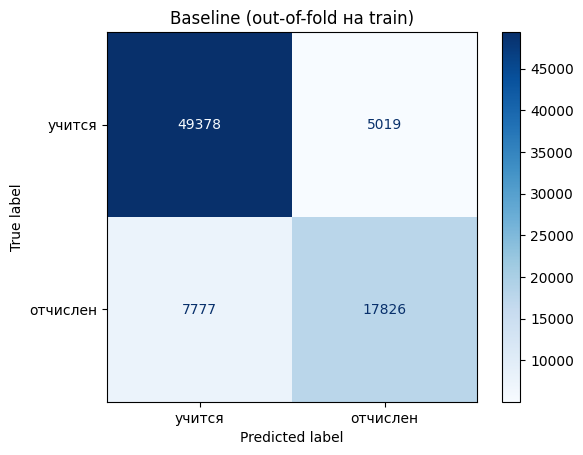

In [34]:
# out-of-fold вероятности: каждый студент train предсказан моделью, которая его не видела
proba_base = oof_proba(pipe_base)
classification_summary(y_train, proba_base, threshold=0.5, title='Baseline (out-of-fold на train)')

<font size="4">

Результат: accuracy 0.840, precision 0.780, recall 0.696, F1 0.736, ROC-AUC 0.904 (разброс между фолдами 0.0017), PR-AUC 0.831

По сравнению с Dummy: PR-AUC 0.83 против 0.32, доля ошибок (1 - accuracy) 0.16 против 0.32, то есть в 2 раза меньше. Модель чему-то научилась

Веса (числовые после StandardScaler, поэтому вес - на 1 std признака; у бинарных и категорий - на переход 0 -> 1):
- самые большие по модулю: `tuition_up_to_date` -0.94, `gpa_semester_1` -0.91, `gpa_semester_2` -0.56, `scholarship_holder` -0.46, `attendance_rate` -0.43, доход High -0.41 / Low +0.34, `first_generation` +0.34, `units_failed` +0.32, `missed_deadlines` +0.32, `lms_logins_per_week` -0.32
- знаки логичные: учеба, посещаемость, оплата и стипендия снижают риск; несданные дисциплины, дедлайны, стресс, часы работы и «первый в семье» - повышают
- демография около нуля, как и думали: страны в пределах +-0.12, пол +-0.10, направления +-0.05, возраст -0.02, дорога 0.03

Гипотеза подтвердилась частично. Неожиданно, что вес оплаты (-0.94) такой же, как у GPA 1 семестра. Но сравнивать их напрямую нельзя: у оплаты это весь эффект (0 -> 1), а у GPA - эффект одного std, а GPA меняется на несколько std (от 0 до 4). `units_failed` получил меньше, чем ждали по EDA - похоже, часть его сигнала забрал GPA

Матрица ошибок (out-of-fold на train, порог 0.5): модель находит 70% отчисленных и пропускает 30% - это 0.304 * 25 603 = ~7 800 студентов. Ложных тревог меньше: precision 0.78, из 5 студентов в группе риска 4 действительно отчисляются. Для нас это не очень хорошо: чаще модель ошибается как раз самой дорогой ошибкой (FN)

</font>

## LogisticRegression (only num features)

<font size="4">

Наблюдение: в baseline большие веса есть не только у числовых признаков. Среди самых сильных - бинарные и категориальные, и почти все они финансовые: `tuition_up_to_date` -0.94, `scholarship_holder` -0.46, доход High -0.41 / Low +0.34, `first_generation` +0.34

Гипотеза: модель только на 18 числовых признаках будет заметно хуже baseline, но не катастрофически:

- главный сигнал - GPA (перепад логита ~6 на графиках) - числовой и останется в модели, поэтому ROC-AUC упадет на сотые, а не на десятые: ожидаем ~0.89 вместо 0.904
- потеря будет больше разброса между фолдами (0.0017): вес оплаты -0.94 означает, что у не оплативших вовремя шанс отчисления в exp(0.94) = 2.6 раза выше, а таких студентов 21.5% (раздел с категориальными признаками) - это слишком большая группа, чтобы ее потеря прошла незаметно
- веса числовых признаков почти не изменятся, если финансовые признаки с ними слабо связаны (в корреляционной матрице и VIF связи не видно)

Эксперимент: LogisticRegression на 18 числовых признаках (без бинарных и категориальных), 5-fold CV, сравнение весов с baseline

</font>

In [35]:
NAME_NUM = 'LR: только числовые'

pipe_num = make_model(LogisticRegression(), bin_cols=[], cat_cols=[])

evaluate(pipe_num, NAME_NUM)
show_results([NAME_DUMMY, NAME_NUM, NAME_BASE])

,accuracy,precision,recall,f1,roc_auc,roc_auc_std,pr_auc
Dummy (most_frequent),0.6800,0.0000,0.0000,0.0000,0.5000,0.0000,0.3200
LR: только числовые,0.8273,0.7640,0.6664,0.7118,0.8912,0.0020,0.8108
LR: базовые признаки,0.8400,0.7803,0.6962,0.7359,0.9039,0.0017,0.8313


In [36]:
pipe_num.fit(X_train, y_train)
B0, B = get_coefs(pipe_num['model'])
names = list(pipe_num[:-1].get_feature_names_out())
print_model(B0, B, names)

Bs = np.hstack([B0, B])
vis_weigths(Bs, names)

# веса числовых признаков: только числовые vs baseline
w_base = pd.Series(pipe_base['model'].coef_[0], index=pipe_base[:-1].get_feature_names_out())
pd.DataFrame({'только числовые': pd.Series(B, index=names), 'baseline': w_base[names]}).round(3)

Решение
-1.317-0.02*age+0.27*weekly_work_hours-0.09*semester-0.14*admission_grade-0.04*previous_qualification_grade-0.06*units_enrolled+0.30*units_failed-0.86*gpa_semester_1-0.58*gpa_semester_2-0.41*attendance_rate-0.26*assignments_submitted_rate-0.21*library_visits_per_month-0.29*lms_logins_per_week+0.29*missed_deadlines+0.28*stress_level-0.20*satisfaction_score+0.03*commute_time_mins-0.05*sleep_hours


,только числовые,baseline
age,-0.023,-0.016
weekly_work_hours,0.272,0.243
semester,-0.094,-0.105
admission_grade,-0.141,-0.098
previous_qualification_grade,-0.043,-0.004
units_enrolled,-0.060,0.013
units_failed,0.301,0.325
gpa_semester_1,-0.857,-0.909
gpa_semester_2,-0.579,-0.556
attendance_rate,-0.413,-0.430


Только числовые (out-of-fold)  threshold = 0.5
              precision    recall  f1-score   support

  0 - учится      0.852     0.903     0.877     54397
1 - отчислен      0.764     0.666     0.712     25603

    accuracy                          0.827     80000
   macro avg      0.808     0.785     0.794     80000
weighted avg      0.824     0.827     0.824     80000



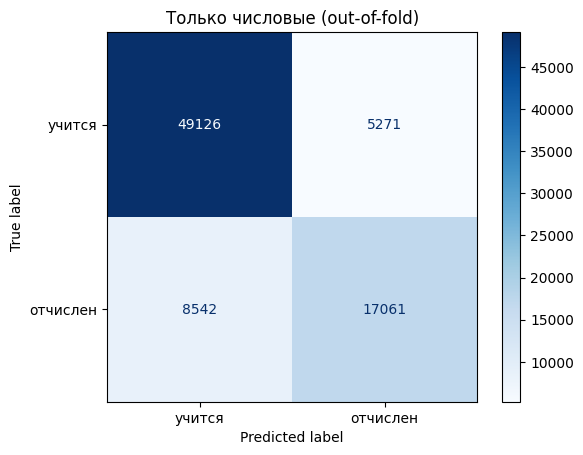

In [37]:
classification_summary(y_train, oof_proba(pipe_num), threshold=0.5, title='Только числовые (out-of-fold)')

<font size="4">

Результат: accuracy 0.827, precision 0.764, recall 0.666, F1 0.712, ROC-AUC 0.891, PR-AUC 0.811

Гипотеза подтвердилась:

- ROC-AUC упала с 0.904 до 0.891 - на 0.013, это в ~8 раз больше разброса между фолдами, то есть не шум. PR-AUC 0.831 -> 0.811, recall 0.696 -> 0.666: без финансовых признаков модель находит на 3% отчисленных меньше (0.03 * 25 603 = ~770 студентов в train)
- веса числовых почти не изменились: `gpa_semester_1` -0.86 (было -0.91), `gpa_semester_2` -0.58 (-0.56), `attendance_rate` -0.41 (-0.43). Значит бинарные и категориальные признаки не повторяют числовые, а добавляют свое
- чуть выросли `satisfaction_score` (-0.15 -> -0.20) и `admission_grade` (-0.10 -> -0.14) - видимо, они немного связаны с финансами и забрали часть их эффекта

Получаем что бинарные и категориальные признаки оставляем

</font>

## LogisticRegression (only gpa_semester_1 feature)

<font size="4">

Наблюдение: в EDA `gpa_semester_1` - самый сильный признак (перепад логита ~6, логит линейный), а у baseline у него один из двух самых больших весов

Гипотеза: один GPA первого семестра даст большую часть качества baseline. GPA второго семестра сам по себе будет чуть слабее (в EDA его перепад логита ~5)

Эксперимент: LogisticRegression только на `gpa_semester_1`, отдельно - только на `gpa_semester_2`. Сравнение Dummy -> 1 признак -> все признаки

</font>

In [38]:
NAME_1F = 'LR: 1 признак gpa_semester_1'

pipe_1f = make_model(LogisticRegression(), num_cols=['gpa_semester_1'], bin_cols=[], cat_cols=[])

evaluate(pipe_1f, NAME_1F)
evaluate(make_model(LogisticRegression(), num_cols=['gpa_semester_2'], bin_cols=[], cat_cols=[]),
         'LR: 1 признак gpa_semester_2')
show_results([NAME_DUMMY, NAME_1F, 'LR: 1 признак gpa_semester_2', NAME_BASE])

,accuracy,precision,recall,f1,roc_auc,roc_auc_std,pr_auc
Dummy (most_frequent),0.6800,0.0000,0.0000,0.0000,0.5000,0.0000,0.3200
LR: 1 признак gpa_semester_1,0.7938,0.7175,0.5867,0.6455,0.8505,0.0016,0.7407
LR: 1 признак gpa_semester_2,0.7716,0.6873,0.5253,0.5954,0.8224,0.0026,0.6936
LR: базовые признаки,0.8400,0.7803,0.6962,0.7359,0.9039,0.0017,0.8313


Решение
-1.148-1.77*gpa_semester_1

вес gpa_semester_1: один признак -1.771, в baseline -0.909


Один признак gpa_semester_1 (out-of-fold)  threshold = 0.5
              precision    recall  f1-score   support

  0 - учится      0.821     0.891     0.855     54397
1 - отчислен      0.717     0.587     0.646     25603

    accuracy                          0.794     80000
   macro avg      0.769     0.739     0.750     80000
weighted avg      0.788     0.794     0.788     80000



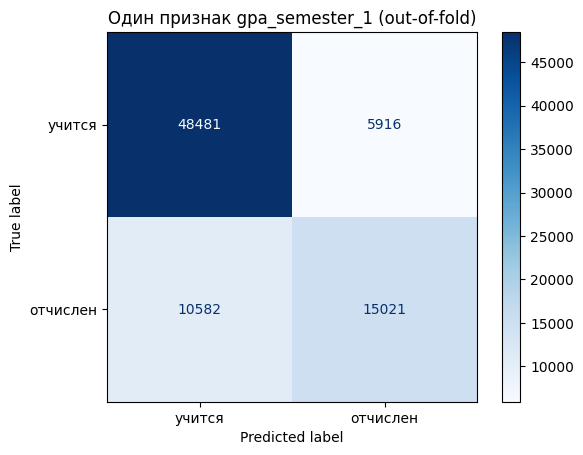

In [39]:
pipe_1f.fit(X_train, y_train)
B0, B = get_coefs(pipe_1f['model'])
print_model(B0, B, list(pipe_1f[:-1].get_feature_names_out()))

# тот же признак в полной модели: вес при одинаковых остальных признаках
w_base = pd.Series(pipe_base['model'].coef_[0], index=pipe_base[:-1].get_feature_names_out())
print(f"\nвес gpa_semester_1: один признак {B[0]:.3f}, в baseline {w_base['gpa_semester_1']:.3f}")

classification_summary(y_train, oof_proba(pipe_1f), threshold=0.5, title='Один признак gpa_semester_1 (out-of-fold)')

<font size="4">

Результат: один `gpa_semester_1` дает ROC-AUC 0.851, PR-AUC 0.741, recall 0.587

Dummy -> 1 признак -> все признаки (какую часть пути от Dummy до полной модели проходит один признак):
- ROC-AUC: 0.50 -> 0.851 -> 0.904, (0.851 - 0.5) / (0.904 - 0.5) = 87%
- PR-AUC: 0.32 -> 0.741 -> 0.831, (0.741 - 0.32) / (0.831 - 0.32) = 82%
- recall: 0 -> 0.587 -> 0.696

Гипотеза подтвердилась: по одному GPA модель уже неплохо ранжирует студентов. Но 41% отчисленных (1 - 0.587) она не находит - для этого и нужны остальные признаки: по одному GPA не отличить слабого студента, который платит и ходит на занятия, от того, кто уйдет. `gpa_semester_2` сам по себе слабее (ROC-AUC 0.822), как и было видно в EDA

Вес `gpa_semester_1` в одиночку -1.77, а в полной модели -0.91, почти в 2 раза меньше. Об этом и был последний пункт вывода по графикам логитов: один признак забирает на себя и эффект связанных с ним признаков (GPA 2 семестра, несданные дисциплины, посещаемость), а в полной модели этот общий сигнал делится

</font>

## LogisticRegression (L1 / L2 regularization)

<font size="4">

Наблюдение: у baseline 54 веса, и многие из них - страны, направления, пол, возраст, дорога - близки к нулю. В EDA эти признаки с отчислением не связаны (графики логитов, распределения категорий)

Гипотеза:

- L1-регуляризация обнулит веса бесполезных признаков, а качество не изменится, пока C не станет совсем маленьким. Сколько весов обнулится, оцениваем по baseline: у ~24 весов из 54 |вес| < 0.05 (считаем в ячейке ниже) - это и есть кандидаты в нули
- сила L2-регуляризации почти ни на что не повлияет: на 80 000 студентов приходится 54 признака, ~1500 объектов на один вес - переобучаться модели не на чем

Эксперимент: L1 (`solver='liblinear'`) и L2 при C от 0.001 до 1, 5-fold CV; для L1 считаем число ненулевых весов. C больше - регуляризация слабее

</font>

In [40]:
# кандидаты в нули по baseline
print('весов baseline с |вес| < 0.05:', (w_base.abs() < 0.05).sum(), 'из', len(w_base))

C_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 1]

reg_rows = []
for penalty in ['l1', 'l2']:
    for C in C_GRID:
        name = f'LR: {penalty.upper()}, C = {C}'
        model = make_model(LogisticRegression(penalty=penalty, C=C, solver='liblinear', random_state=42))
        evaluate(model, name)
        # сколько весов осталось ненулевыми при обучении на всем train
        n_nonzero = (model.fit(X_train, y_train)['model'].coef_[0] != 0).sum()
        reg_rows.append({'penalty': penalty, 'C': C, 'ненулевых весов': n_nonzero, **results[name]})

reg_table = pd.DataFrame(reg_rows)
reg_table[['penalty', 'C', 'ненулевых весов', 'precision', 'recall', 'f1', 'roc_auc', 'roc_auc_std', 'pr_auc']].round(4)

весов baseline с |вес| < 0.05: 24 из 54


,penalty,C,ненулевых весов,precision,recall,f1,roc_auc,roc_auc_std,pr_auc
0,l1,0.001,16,0.7733,0.6748,0.7207,0.8973,0.0024,0.8202
1,l1,0.003,21,0.7818,0.6895,0.7327,0.9025,0.0020,0.8291
2,l1,0.010,26,0.7819,0.6954,0.7361,0.9038,0.0018,0.8313
3,l1,0.030,32,0.7811,0.6954,0.7358,0.9040,0.0018,0.8315
4,l1,0.100,41,0.7806,0.6959,0.7358,0.9039,0.0017,0.8314
5,l1,1.000,51,0.7805,0.6965,0.7361,0.9039,0.0017,0.8313
6,l2,0.001,54,0.7852,0.6832,0.7306,0.9030,0.0019,0.8300
7,l2,0.003,54,0.7829,0.6907,0.7339,0.9037,0.0018,0.8311
8,l2,0.010,54,0.7809,0.6946,0.7352,0.9039,0.0017,0.8314
9,l2,0.030,54,0.7807,0.6955,0.7356,0.9039,0.0017,0.8314


In [41]:
fig = px.line(reg_table, x='C', y='roc_auc', color='penalty', markers=True, log_x=True, text='ненулевых весов',
              title='ROC-AUC на CV в зависимости от C (подпись - число ненулевых весов)')
fig.update_traces(textposition='top center')
fig.update_layout(template='plotly_dark', height=500)
fig.show()

In [42]:
NAME_L1 = 'LR: L1, C = 0.01'

# веса L1 при C = 0.01 - самое сильное сжатие, при котором качество еще не упало
pipe_l1 = make_model(LogisticRegression(penalty='l1', C=0.01, solver='liblinear', random_state=42)).fit(X_train, y_train)
B0, B = get_coefs(pipe_l1['model'])
names = list(pipe_l1[:-1].get_feature_names_out())
print_model(B0, B, names)

Bs = np.hstack([B0, B])
vis_weigths(Bs, names, width=1500)

w_l1 = pd.Series(B, index=names)
print('обнулены:', ', '.join(w_l1[w_l1 == 0].index))
print('\nостались, но |вес| < 0.05:', ', '.join(f'{k} ({v:.3f})' for k, v in w_l1[(w_l1 != 0) & (w_l1.abs() < 0.05)].items()))

Решение
-0.136-0.01*age+0.23*weekly_work_hours-0.09*semester-0.09*admission_grade+0.00*previous_qualification_grade+0.00*units_enrolled+0.31*units_failed-0.90*gpa_semester_1-0.54*gpa_semester_2-0.41*attendance_rate-0.27*assignments_submitted_rate-0.21*library_visits_per_month-0.30*lms_logins_per_week+0.30*missed_deadlines+0.25*stress_level-0.14*satisfaction_score+0.02*commute_time_mins-0.04*sleep_hours+0.27*first_generation+0.01*disability_status-0.42*scholarship_holder-0.92*tuition_up_to_date+0.00*international_student-0.27*extracurricular_activities+0.00*mental_health_support+0.00*gender_Female-0.00*gender_Male+0.00*gender_Other+0.00*nationality_Australia+0.00*nationality_Brazil+0.00*nationality_Canada+0.00*nationality_China+0.00*nationality_Egypt+0.00*nationality_Germany+0.00*nationality_India+0.00*nationality_Indonesia+0.00*nationality_Mexico+0.00*nationality_Nigeria+0.00*nationality_Pakistan+0.00*nationality_Philippines+0.00*nationality_South Korea+0.00*nationality_UK+0.00*nationa

обнулены: previous_qualification_grade, units_enrolled, international_student, mental_health_support, gender_Female, gender_Other, nationality_Australia, nationality_Brazil, nationality_Canada, nationality_China, nationality_Egypt, nationality_Germany, nationality_India, nationality_Indonesia, nationality_Mexico, nationality_Nigeria, nationality_Pakistan, nationality_Philippines, nationality_South Korea, nationality_UK, nationality_USA, course_type_Arts & Humanities, course_type_Business, course_type_Health Sciences, course_type_Law & Social Sciences, course_type_STEM, study_mode_Online, study_mode_Part-time

остались, но |вес| < 0.05: age (-0.006), commute_time_mins (0.019), sleep_hours (-0.043), disability_status (0.010), gender_Male (-0.001)


<font size="4">

Результат:

- L2: при C от 1 до 0.01 ROC-AUC не меняется (0.9039), только при C = 0.001 немного падает (0.9030). Сила регуляризации тут не важна - гипотеза подтвердилась
- L1: при C = 0.01 осталось 26 ненулевых весов из 54 (обнулено 28, оценка была ~24), а качество то же: ROC-AUC 0.9038, PR-AUC 0.8313. Дальше качество падает: C = 0.003 - 21 вес и 0.9025, C = 0.001 - 16 весов и 0.8973, начинают обнуляться полезные признаки

L1 обнулила все страны, все направления, пол Female / Other, формы обучения Online / Part-time, `previous_qualification_grade`, `units_enrolled`, `international_student`, `mental_health_support`. Почти нулевые веса остались у возраста, дороги, сна, инвалидности и `gender_Male`. Это те же признаки, у которых в EDA не было связи с отчислением - гипотеза подтвердилась

Из интересного: из формы обучения L1 оставила только `study_mode_Full-time` (-0.16), то есть важно только, очная форма или нет. И обнулила `units_enrolled`: если известно число несданных, общее число дисциплин ничего не добавляет

По метрикам L1 ничего не улучшила, зато показала, что половина признаков не нужна. Проверяем это в следующей модели

</font>

## LogisticRegression (without useless features)

<font size="4">

Наблюдение: L1 при C = 0.01 обнулила или почти обнулила (|вес| < 0.05) веса больше половины столбцов и при этом не потеряла качество

Гипотеза: модель только на признаках, которые L1 оставила, будет такой же по качеству, как baseline - разница в пределах разброса между фолдами (`roc_auc_std` ~0.002), потому что удаляемые признаки и так давали в логит меньше 0.05 каждый. Признаков станет примерно вдвое меньше: из 54 столбцов слабых ~31. Категориальный признак удаляем целиком, если слабые все его категории

Эксперимент: LogisticRegression (L2, C = 1) на признаках с |вес L1| >= 0.05, 5-fold CV

</font>

In [43]:
NAME_SHORT = 'LR: без бесполезных признаков'

weak = set(w_l1[w_l1.abs() < 0.05].index)
num_short = [col for col in num_model if col not in weak]
bin_short = [col for col in binary_model if col not in weak]
# категориальный признак оставляем, если хотя бы одна его категория не слабая
cat_short = [col for col in cat_model
             if not all(name in weak for name in w_l1.index if name.startswith(col + '_'))]

print('удалены:', [col for col in num_model + binary_model + cat_model if col not in num_short + bin_short + cat_short])

pipe_short = make_model(LogisticRegression(), num_cols=num_short, bin_cols=bin_short, cat_cols=cat_short)

evaluate(pipe_short, NAME_SHORT)
show_results([NAME_DUMMY, NAME_BASE, NAME_L1, NAME_SHORT])

удалены: ['age', 'previous_qualification_grade', 'units_enrolled', 'commute_time_mins', 'sleep_hours', 'disability_status', 'international_student', 'mental_health_support', 'gender', 'nationality', 'course_type']


,accuracy,precision,recall,f1,roc_auc,roc_auc_std,pr_auc
Dummy (most_frequent),0.6800,0.0000,0.0000,0.0000,0.5000,0.0000,0.3200
LR: базовые признаки,0.8400,0.7803,0.6962,0.7359,0.9039,0.0017,0.8313
"LR: L1, C = 0.01",0.8404,0.7819,0.6954,0.7361,0.9038,0.0018,0.8313
LR: без бесполезных признаков,0.8402,0.7806,0.6966,0.7362,0.9039,0.0017,0.8313


In [44]:
pipe_short.fit(X_train, y_train)
B0, B = get_coefs(pipe_short['model'])
names = list(pipe_short[:-1].get_feature_names_out())
print_model(B0, B, names)

Bs = np.hstack([B0, B])
vis_weigths(Bs, names)

Решение
-0.204+0.25*weekly_work_hours-0.10*semester-0.10*admission_grade+0.33*units_failed-0.91*gpa_semester_1-0.55*gpa_semester_2-0.43*attendance_rate-0.28*assignments_submitted_rate-0.22*library_visits_per_month-0.32*lms_logins_per_week+0.32*missed_deadlines+0.27*stress_level-0.15*satisfaction_score+0.34*first_generation-0.46*scholarship_holder-0.94*tuition_up_to_date-0.29*extracurricular_activities-0.44*family_income_level_High+0.32*family_income_level_Low-0.09*family_income_level_Middle-0.19*study_mode_Full-time-0.03*study_mode_Online+0.01*study_mode_Part-time


Без бесполезных признаков (out-of-fold)  threshold = 0.5
              precision    recall  f1-score   support

  0 - учится      0.864     0.908     0.885     54397
1 - отчислен      0.781     0.697     0.736     25603

    accuracy                          0.840     80000
   macro avg      0.822     0.802     0.811     80000
weighted avg      0.837     0.840     0.838     80000



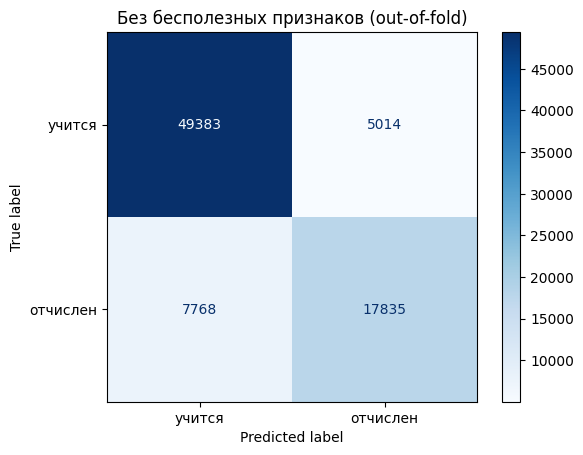

In [45]:
proba_short = oof_proba(pipe_short)
classification_summary(y_train, proba_short, threshold=0.5, title='Без бесполезных признаков (out-of-fold)')

<font size="4">

Результат: удалено 11 исходных признаков (8 числовых и бинарных + пол, страна, направление), столбцов стало 23 вместо 54. Метрики те же: ROC-AUC 0.9039, PR-AUC 0.8313, F1 0.7362 против 0.7359 - разница в 4-м знаке при разбросе между фолдами 0.0017. Матрица ошибок почти такая же, как у baseline

Гипотеза подтвердилась:
- удаленные признаки модель и так почти не использовала
- веса оставшихся почти не поменялись: `tuition_up_to_date` -0.94, `gpa_semester_1` -0.91, `gpa_semester_2` -0.55. Немного сдвинулся доход (High -0.41 -> -0.44) - к нему перешли мелкие эффекты удаленных признаков

При одинаковом качестве лучше простая модель: про нового студента нужно знать в 2 раза меньше, веса проще читать. Плюс модель не использует пол и страну, что для решений про людей тоже хорошо. Это кандидат в финальную модель

</font>

## LogisticRegression (early warning: question 1)

<font size="4">

Это скорее не попытка улучшить модель, а попытка ответить на вопрос исследования 1: насколько рано можно заметить отчисление

Наблюдение: в EDA GPA первого семестра разделяет классы почти так же хорошо, как GPA второго (перепад логита ~6 и ~5), и они сильно связаны (r = 0.83). В таблице GPA 1 x GPA 2 первый семестр сдвигает долю отчисленных сильнее второго (79% -> 16% против 79% -> 45%)

Гипотеза:

- модель «после первого семестра» (без `gpa_semester_2`) потеряет мало - ROC-AUC упадет на тысячные, а не на сотые: при r = 0.83 большую часть информации GPA 2 уже несет GPA 1
- модель «при поступлении» (только то, что известно в день зачисления: демография, финансы, баллы при поступлении, работа и дорога - без успеваемости и вовлеченности) потеряет много: из нее уходит GPA, который один дает ROC-AUC 0.85. Ожидаем ROC-AUC ближе к 0.7, чем к 0.9

Эксперимент: модель без бесполезных признаков без `gpa_semester_2`; модель на признаках при поступлении; 5-fold CV

</font>

In [46]:
NAME_SEM1 = 'LR: после 1 семестра (без gpa_semester_2)'
NAME_ADM = 'LR: при поступлении'

pipe_sem1 = make_model(LogisticRegression(),
                       num_cols=[col for col in num_short if col != 'gpa_semester_2'], bin_cols=bin_short, cat_cols=cat_short)

# известно в день зачисления: без успеваемости, вовлеченности и самочувствия
admission_num = ['age', 'admission_grade', 'previous_qualification_grade', 'weekly_work_hours', 'commute_time_mins']
admission_bin = ['first_generation', 'disability_status', 'scholarship_holder', 'tuition_up_to_date', 'international_student']
pipe_adm = make_model(LogisticRegression(), num_cols=admission_num, bin_cols=admission_bin, cat_cols=cat_model)

evaluate(pipe_sem1, NAME_SEM1)
evaluate(pipe_adm, NAME_ADM)
show_results([NAME_DUMMY, NAME_ADM, NAME_SEM1, NAME_SHORT])

,accuracy,precision,recall,f1,roc_auc,roc_auc_std,pr_auc
Dummy (most_frequent),0.6800,0.0000,0.0000,0.0000,0.5000,0.0000,0.3200
LR: при поступлении,0.7029,0.5870,0.2424,0.3430,0.6888,0.0047,0.5073
LR: после 1 семестра (без gpa_semester_2),0.8362,0.7750,0.6878,0.7288,0.9007,0.0014,0.8261
LR: без бесполезных признаков,0.8402,0.7806,0.6966,0.7362,0.9039,0.0017,0.8313


<font size="4">

Результат:
- после 1 семестра: ROC-AUC 0.9007 против 0.9039, PR-AUC 0.826 против 0.831, recall 0.688 против 0.697 - потеря в тысячных
- при поступлении: ROC-AUC 0.689, PR-AUC 0.507, recall 0.24 - лучше Dummy, но примерно посередине между Dummy и полной моделью

Гипотеза подтвердилась. Ответ на **вопрос 1**: заметить отчисление можно уже после первого семестра почти без потерь - GPA второго семестра в основном повторяет первый. А в день зачисления модель видит в основном финансы, и этого мало: главная информация появляется уже во время учебы

Оговорка: в данных не сказано, когда измеряются посещаемость, сданные задания и `units_failed`. Мы убрали только GPA второго семестра, если остальное тоже собирается в конце года, ранняя модель потеряет больше

</font>

## Сравнение моделей и выбор финальной

In [47]:
candidates = [NAME_DUMMY, NAME_ADM, NAME_1F, NAME_NUM, NAME_SEM1, NAME_BASE, NAME_L1, NAME_SHORT]

cv_table = show_results(candidates)
cv_table['pr_auc_std'] = [results[name]['pr_auc_std'] for name in candidates]
# сложность модели - сколько столбцов она видит после preprocessing (у Dummy - 0, у L1 - только ненулевые веса)
cv_table['n_features'] = [0 if name == NAME_DUMMY else
                          int((pipe_l1['model'].coef_[0] != 0).sum()) if name == NAME_L1 else
                          n_features(models[name]) for name in candidates]
cv_table = cv_table.sort_values('pr_auc')
display(cv_table)

fig = px.bar(cv_table.reset_index(names='model'), x='pr_auc', y='model', orientation='h',
             error_x='pr_auc_std', text='n_features',
             title='5-fold CV: PR-AUC +- разброс между folds (подпись - число признаков)')
fig.add_vline(x=y_train.mean(), line_dash='dash', annotation_text='доля отчисленных (случайная модель)')
fig.update_layout(template='plotly_dark', height=550, yaxis_title='')
fig.show()

,accuracy,precision,recall,f1,roc_auc,roc_auc_std,pr_auc,pr_auc_std,n_features
Dummy (most_frequent),0.6800,0.0000,0.0000,0.0000,0.5000,0.0000,0.3200,0.000031,0
LR: при поступлении,0.7029,0.5870,0.2424,0.3430,0.6888,0.0047,0.5073,0.005972,39
LR: 1 признак gpa_semester_1,0.7938,0.7175,0.5867,0.6455,0.8505,0.0016,0.7407,0.001680,1
LR: только числовые,0.8273,0.7640,0.6664,0.7118,0.8912,0.0020,0.8108,0.002122,18
LR: после 1 семестра (без gpa_semester_2),0.8362,0.7750,0.6878,0.7288,0.9007,0.0014,0.8261,0.001352,22
LR: базовые признаки,0.8400,0.7803,0.6962,0.7359,0.9039,0.0017,0.8313,0.001844,54
"LR: L1, C = 0.01",0.8404,0.7819,0.6954,0.7361,0.9038,0.0018,0.8313,0.001822,26
LR: без бесполезных признаков,0.8402,0.7806,0.6966,0.7362,0.9039,0.0017,0.8313,0.001855,23


<font size="4">

Модели сравниваем по PR-AUC и ROC-AUC - они не зависят от порога, а порог подберем уже для выбранной модели

Результат: по PR-AUC не отличаются три модели - baseline (54 признака), L1 с C = 0.01 (26 ненулевых весов) и без бесполезных признаков (23), у всех 0.8313 при разбросе между фолдами 0.0019. Остальные уже заметно хуже: только числовые (0.811), после 1 семестра (0.826), один признак (0.741), при поступлении (0.507)

**Финальная модель - `LR: без бесполезных признаков`** (LogisticRegression, L2, C = 1, 23 признака: 13 числовых, 4 бинарных, доход и форма обучения), потому что:
- качество как у baseline, а признаков 23 вместо 54. Меньше уже нельзя: при C = 0.003 L1 теряет 0.0014 ROC-AUC
- в отличие от L1-модели, ей не нужны на входе пол, страна и направление - L1 их веса обнуляет, но сами данные все равно требует
- модель не использует пол и страну

Дальше работаем только с ней: порог, test, веса и ошибки

</font>

In [48]:
NAME_FINAL = NAME_SHORT
pipe_final = models[NAME_FINAL]

print('финальная модель:', NAME_FINAL)
print('признаки:', num_short + bin_short + cat_short)
print('столбцов после предобработки:', n_features(pipe_final))

финальная модель: LR: без бесполезных признаков
признаки: ['weekly_work_hours', 'semester', 'admission_grade', 'units_failed', 'gpa_semester_1', 'gpa_semester_2', 'attendance_rate', 'assignments_submitted_rate', 'library_visits_per_month', 'lms_logins_per_week', 'missed_deadlines', 'stress_level', 'satisfaction_score', 'first_generation', 'scholarship_holder', 'tuition_up_to_date', 'extracurricular_activities', 'family_income_level', 'study_mode']
столбцов после предобработки: 23


## Подбор threshold

<font size="4">

Наблюдение: при пороге 0.5 финальная модель находит только ~70% отчисленных (recall 0.697), а пропущенный отчисленный (FN) для нас дороже ложной тревоги (FP)

Гипотеза: если снизить порог, recall вырастет, но в группу риска будет попадать все больше благополучных студентов. Нужен порог, при котором модель находит большую часть отчисленных, а список для кураторов не раздувается. Ориентир - доля отчисленных 0.32

Эксперимент: метрики при порогах 0.10-0.90 на out-of-fold вероятностях train (test не трогаем) и распределение вероятностей по классам

</font>

In [49]:
# out-of-fold вероятности финальной модели на train: порог подбираем на них, test не трогаем
proba_final = oof_proba(pipe_final)

threshold_rows = []
for t in np.arange(0.10, 0.91, 0.05):
    row = threshold_metrics(y_train, proba_final, t)
    threshold_rows.append({'threshold': round(t, 2), **{k: row[k] for k in ['precision', 'recall', 'f1', 'flagged']}})

threshold_table = pd.DataFrame(threshold_rows)
threshold_table.round(3)

,threshold,precision,recall,f1,flagged
0,0.10,0.502,0.959,0.659,0.611
1,0.15,0.553,0.932,0.694,0.539
2,0.20,0.594,0.902,0.717,0.485
3,0.25,0.631,0.871,0.732,0.442
4,0.30,0.666,0.839,0.743,0.403
5,0.35,0.696,0.804,0.746,0.370
6,0.40,0.726,0.769,0.747,0.339
7,0.45,0.755,0.734,0.745,0.311
8,0.50,0.781,0.697,0.736,0.286
9,0.55,0.804,0.654,0.721,0.260


In [50]:
fig = px.line(threshold_table, x='threshold', y=['precision', 'recall', 'f1', 'flagged'], markers=True,
              title='Precision / Recall / F1 и доля студентов в группе риска при разных threshold (out-of-fold)')
fig.add_vline(x=0.5, line_dash='dash', annotation_text='0.5')
fig.add_vline(x=0.3, line_dash='dot', annotation_text='0.3')
fig.update_layout(template='plotly_dark', height=500, yaxis_title='значение', legend_title='')
fig.show()

In [51]:
prob_frame = pd.DataFrame({'p_dropout': proba_final,
                           'true_class': np.where(y_train == 1, '1 - отчислен', '0 - учится')})

fig = px.histogram(prob_frame, x='p_dropout', color='true_class', nbins=50, barmode='overlay', opacity=0.65,
                   color_discrete_map={'0 - учится': 'steelblue', '1 - отчислен': 'coral'},
                   title='Распределение P(отчисление) по истинным классам (out-of-fold на train)')
fig.add_vline(x=0.5, line_dash='dash', annotation_text='0.5')
fig.add_vline(x=0.3, line_dash='dot', annotation_text='0.3')
fig.update_layout(template='plotly_dark', height=500, xaxis_title='P(отчисление)', yaxis_title='студентов',
                  legend_title='истинный класс')
fig.show()

<font size="4">

Результат:

- таблица: при пороге 0.5 модель находит 70% отчисленных, в группу риска попадает 29% студентов. При 0.3 - recall 0.84, precision 0.67, в группе риска 40%. При 0.2 - recall 0.90, но precision 0.59 и в группе риска уже почти половина студентов (49%), такой список бесполезен
- F1 почти не меняется от 0.30 до 0.45 (0.743-0.747), поэтому в этом диапазоне порог выбираем по цене ошибок, а не по качеству
- распределение вероятностей: отчисленные в основном у 1, оставшиеся у 0, но в зоне 0.2-0.6 классы сильно перекрываются. Чисто разделить их порогом нельзя, можно только выбрать, какую ошибку делать чаще

Выбираем **threshold = 0.3** - он близок к доле отчисленных (0.32). Recall 0.84 значит, что модель находит примерно 5 из 6 отчисленных, precision 0.67 - что 2 из 3 бесед куратора будут по делу. Порог зафиксирован до проверки на test

</font>

Финальная модель (out-of-fold)  threshold = 0.3
              precision    recall  f1-score   support

  0 - учится      0.914     0.802     0.854     54397
1 - отчислен      0.666     0.839     0.743     25603

    accuracy                          0.814     80000
   macro avg      0.790     0.820     0.798     80000
weighted avg      0.834     0.814     0.818     80000



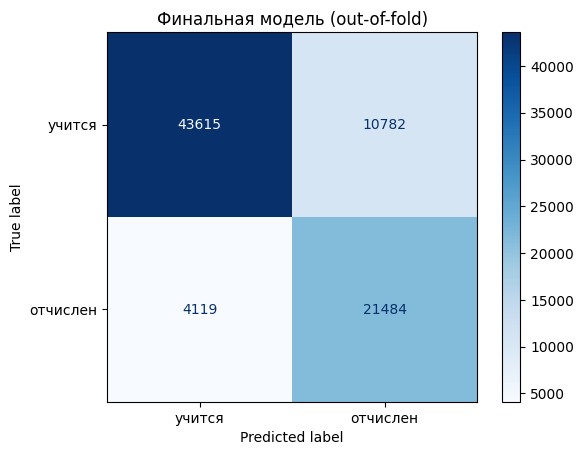

In [52]:
THRESHOLD = 0.3

classification_summary(y_train, proba_final, threshold=THRESHOLD, title='Финальная модель (out-of-fold)')

<font size="4">

По сравнению с порогом 0.5: recall 0.70 -> 0.84, precision 0.78 -> 0.67, F1 0.736 -> 0.743. Accuracy упала (0.84 -> 0.81), но это нормально: accuracy считает FN и FP одинаково, а нам пропущенный студент обходится дороже лишней беседы

Сколько это стоит (по таблице порогов):

- дополнительно нашли отчисленных: (0.839 - 0.697) * 25 603 = ~3 600
- дополнительно попали в группу риска: (0.403 - 0.286) * 80 000 = ~9 400, из них ложных тревог 9 400 - 3 600 = ~5 700
- на каждого дополнительно найденного студента приходится 5 700 / 3 600 = ~1.6 лишней беседы - для нас это приемлемо

</font>

## Финальная модель на test data

In [53]:
# финальная модель обучается на всем train, порог THRESHOLD выбран выше
final_model = clone(pipe_final).fit(X_train, y_train)
baseline_model = clone(models[NAME_BASE]).fit(X_train, y_train)
dummy_model = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)

proba_test = final_model.predict_proba(X_test)[:, 1]
proba_test_base = baseline_model.predict_proba(X_test)[:, 1]

test_table = pd.DataFrame({
    'Dummy (most_frequent)': threshold_metrics(y_test, dummy_model.predict_proba(X_test)[:, 1], 0.5),
    'baseline, threshold 0.5': threshold_metrics(y_test, proba_test_base, 0.5),
    'final, threshold 0.5': threshold_metrics(y_test, proba_test, 0.5),
    f'final, threshold {THRESHOLD}': threshold_metrics(y_test, proba_test, THRESHOLD),
}).T
test_table['CV pr_auc'] = [results[NAME_DUMMY]['pr_auc'], results[NAME_BASE]['pr_auc'],
                           results[NAME_FINAL]['pr_auc'], results[NAME_FINAL]['pr_auc']]
test_table.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc,flagged,CV pr_auc
Dummy (most_frequent),0.6800,0.0000,0.0000,0.0000,0.500,0.3200,0.0000,0.3200
"baseline, threshold 0.5",0.8404,0.7816,0.6955,0.7361,0.903,0.8315,0.2848,0.8313
"final, threshold 0.5",0.8406,0.7820,0.6960,0.7365,0.903,0.8314,0.2848,0.8313
"final, threshold 0.3",0.8134,0.6661,0.8364,0.7416,0.903,0.8314,0.4019,0.8313


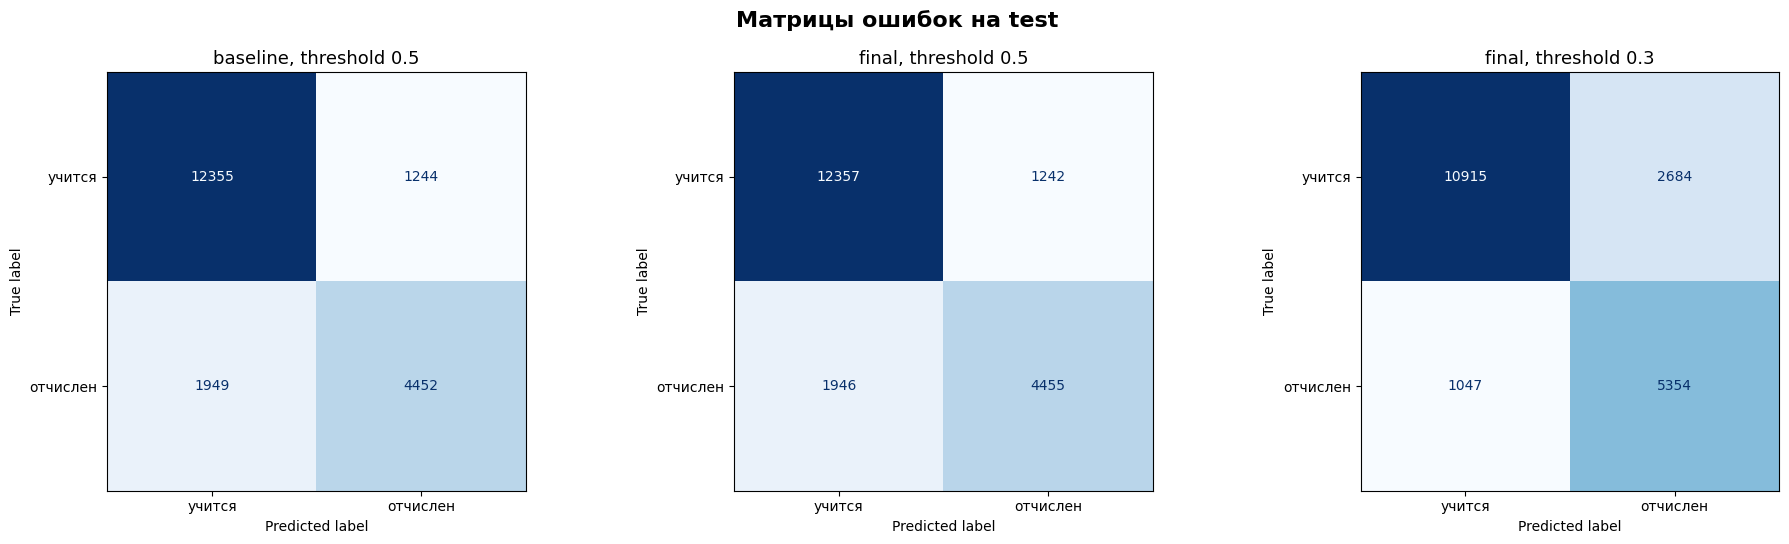

final, threshold 0.3
              precision    recall  f1-score   support

  0 - учится      0.912     0.803     0.854     13599
1 - отчислен      0.666     0.836     0.742      6401

    accuracy                          0.813     20000
   macro avg      0.789     0.820     0.798     20000
weighted avg      0.834     0.813     0.818     20000



In [54]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, proba, t, title in [(axes[0], proba_test_base, 0.5, 'baseline, threshold 0.5'),
                            (axes[1], proba_test, 0.5, 'final, threshold 0.5'),
                            (axes[2], proba_test, THRESHOLD, f'final, threshold {THRESHOLD}')]:
    ConfusionMatrixDisplay.from_predictions(y_test, (proba >= t).astype(int), display_labels=['учится', 'отчислен'],
                                            cmap='Blues', values_format='d', ax=ax, colorbar=False)
    ax.set_title(title, fontsize=13)
plt.suptitle('Матрицы ошибок на test', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'final, threshold {THRESHOLD}')
print(classification_report(y_test, (proba_test >= THRESHOLD).astype(int),
                            target_names=['0 - учится', '1 - отчислен'], digits=3))

<font size="4">

Результат на test (порог 0.3): recall 0.836, precision 0.666, F1 0.742, ROC-AUC 0.903, PR-AUC 0.831

- Dummy -> baseline -> final: PR-AUC 0.32 -> 0.8315 -> 0.8314. Финальная модель не хуже baseline при вдвое меньшем числе признаков, как и было на CV
- PR-AUC на test (0.8314) совпал с CV (0.8313) - оценке по CV можно верить, и на новых студентах из того же распределения качество будет таким же
- матрицы ошибок: baseline и final при пороге 0.5 почти одинаковые (1949 и 1946 FN, 1244 и 1242 FP). Порог 0.3 уменьшает число пропущенных с 1946 до 1047, на (1946 - 1047) / 1946 = 46%, а ложных тревог становится больше: 1242 -> 2684. Соотношение как на CV: 1442 / 899 = ~1.6 лишней беседы на одного найденного
- в итоге из 6401 отчисленного в test модель нашла 5354 (84%). В группу риска попало 5354 + 2684 = 8038 студентов (40% test), из них 2 из 3 действительно отчисляются

</font>

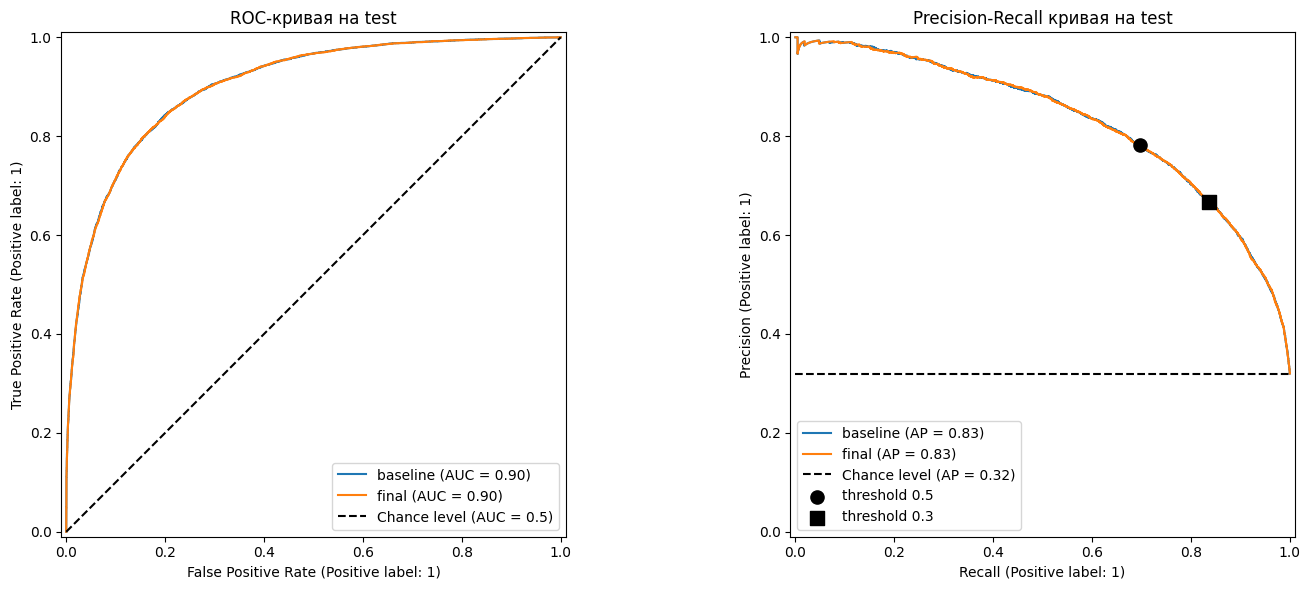

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

RocCurveDisplay.from_predictions(y_test, proba_test_base, name='baseline', ax=axes[0])
RocCurveDisplay.from_predictions(y_test, proba_test, name='final', ax=axes[0], plot_chance_level=True)
axes[0].set_title('ROC-кривая на test')

PrecisionRecallDisplay.from_predictions(y_test, proba_test_base, name='baseline', ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, proba_test, name='final', ax=axes[1], plot_chance_level=True)
# рабочие точки модели: threshold 0.5 и выбранный
for t, marker in [(0.5, 'o'), (THRESHOLD, 's')]:
    pred = (proba_test >= t).astype(int)
    axes[1].scatter(recall_score(y_test, pred), precision_score(y_test, pred), s=90, marker=marker, color='black',
                    zorder=5, label=f'threshold {t}')
axes[1].legend(loc='lower left')
axes[1].set_title('Precision-Recall кривая на test')

plt.tight_layout()
plt.show()

<font size="4">

- ROC- и PR-кривые baseline и финальной модели совпадают полностью: 54 - 23 = 31 удаленный столбец ничего не давал
- ROC-AUC 0.90, AP 0.83 при 0.32 у случайной модели (пунктир)
- точки порогов 0.5 и 0.3 лежат на одной PR-кривой: порог не меняет модель, а только выбирает точку на кривой. После recall ~0.85 кривая резко идет вниз, и каждый следующий процент recall стоит все больше precision. Поэтому ниже 0.3 порог не опускаем

</font>

In [56]:
B0, B = get_coefs(final_model['model'])
final_names = list(final_model[:-1].get_feature_names_out())
print_model(B0, B, final_names)

Bs = np.hstack([B0, B])
vis_weigths(Bs, final_names)

Решение
-0.204+0.25*weekly_work_hours-0.10*semester-0.10*admission_grade+0.33*units_failed-0.91*gpa_semester_1-0.55*gpa_semester_2-0.43*attendance_rate-0.28*assignments_submitted_rate-0.22*library_visits_per_month-0.32*lms_logins_per_week+0.32*missed_deadlines+0.27*stress_level-0.15*satisfaction_score+0.34*first_generation-0.46*scholarship_holder-0.94*tuition_up_to_date-0.29*extracurricular_activities-0.44*family_income_level_High+0.32*family_income_level_Low-0.09*family_income_level_Middle-0.19*study_mode_Full-time-0.03*study_mode_Online+0.01*study_mode_Part-time


In [57]:
# вопрос 2: сколько GPA «стоит» бедность - переводим разницу весов дохода в баллы GPA 1 семестра
w_final = pd.Series(B, index=final_names)
gpa1_std = final_model['preprocessors'].named_transformers_['num']['scaler'].scale_[num_short.index('gpa_semester_1')]
gpa1_per_point = w_final['gpa_semester_1'] / gpa1_std     # вес на 1 балл GPA, а не на 1 std
income_gap = w_final['family_income_level_Low'] - w_final['family_income_level_High']

print(f'std gpa_semester_1 в train: {gpa1_std:.3f}')
print(f'вес gpa_semester_1 на 1 балл: {w_final["gpa_semester_1"]:.3f} / {gpa1_std:.3f} = {gpa1_per_point:.3f}')
print(f'Low - High: {income_gap:.3f} -> бедность «стоит» {income_gap:.3f} / {-gpa1_per_point:.3f} = '
      f'{income_gap / -gpa1_per_point:.2f} балла GPA 1 семестра при прочих равных')

std gpa_semester_1 в train: 0.788
вес gpa_semester_1 на 1 балл: -0.910 / 0.788 = -1.155
Low - High: 0.759 -> бедность «стоит» 0.759 / 1.155 = 0.66 балла GPA 1 семестра при прочих равных


<font size="4">

Веса финальной модели (числовые - на 1 std, бинарные и категории - на переход 0 -> 1). Во сколько раз меняется шанс отчисления - это exp(вес):

- сильнее всего снижают риск: оплата вовремя (exp(-0.94) = 0.39, шанс ниже в 1 / 0.39 = 2.5 раза), GPA 1 семестра (тоже в ~2.5 раза на 1 std), GPA 2 семестра (exp(-0.55) = 0.58, в 1.7 раза), стипендия, высокий доход, посещаемость (примерно в 1.5 раза каждый)
- сильнее всего повышают: «первый в семье» (exp(0.34) = 1.41), несданные дисциплины (1.39 на 1 std), низкий доход (1.38), пропущенные дедлайны (1.37 на 1 std), стресс (1.31), часы работы (1.28)
- в баллах: 1 std GPA 1 семестра = 0.79 балла, поэтому вес на 1 балл = -0.91 / 0.79 = -1.155, и каждый балл GPA снижает шанс отчисления в exp(1.155) = ~3.2 раза
- доход и форма обучения закодированы всеми категориями, поэтому смотрим только на разности весов: Low - High = 0.76, Full-time против остальных форм ~ -0.2

**Ответ на вопрос 2**: при прочих равных бедность «стоит» 0.76 / 1.155 = 0.66 балла GPA первого семестра: студент из семьи Low с GPA 3.0 рискует так же, как студент из семьи High с GPA 3.0 - 0.66 = ~2.3. В EDA получалось примерно полбалла - модель это подтвердила, доход влияет сам по себе, а не через оценки. Но учеба весит больше: разница между GPA 2 и GPA 4 это 2 * 1.155 = 2.3 в логите, в 3 раза больше, чем между бедной и обеспеченной семьей (0.76)

**Вопрос 3** тоже видно по весам: `missed_deadlines` входит в модель линейно, +0.32 на 1 std (2.6 дедлайна), то есть каждый дедлайн добавляет к логиту примерно 0.32 / 2.6 = ~0.12. Скачок «0 -> 1», который был на графике логита, в полной модели объясняют другие признаки: у студентов без пропущенных дедлайнов в среднем и GPA выше, и посещаемость лучше. Подробнее - на новых объектах ниже

Оговорка: веса показывают связь, а не причину. Например, неоплата может быть следствием того, что студент уже решил уйти

</font>

## Анализ ошибок

In [58]:
error_df = X_test.copy()
error_df['y_true'] = y_test
error_df['proba'] = proba_test
error_df['y_pred'] = (proba_test >= THRESHOLD).astype(int)
error_df['outcome'] = np.select(
    [(error_df['y_true'] == 1) & (error_df['y_pred'] == 1), (error_df['y_true'] == 1) & (error_df['y_pred'] == 0),
     (error_df['y_true'] == 0) & (error_df['y_pred'] == 1)],
    ['TP - нашли', 'FN - пропустили', 'FP - ложная тревога'], default='TN - верно «учится»')
error_df['gpa_group'] = pd.cut(error_df['gpa_semester_1'], bins=[-0.01, 2, 2.5, 3, 4.01],
                               labels=['GPA < 2', 'GPA 2 - 2.5', 'GPA 2.5 - 3', 'GPA 3+'])

# портрет каждой группы: средние значения главных признаков
profile_cols = ['gpa_semester_1', 'gpa_semester_2', 'units_failed', 'attendance_rate', 'missed_deadlines',
                'tuition_up_to_date', 'scholarship_holder', 'proba']
profile = error_df.groupby('outcome')[profile_cols].mean()
profile.insert(0, 'студентов', error_df['outcome'].value_counts())
profile.round(2)

,студентов,gpa_semester_1,gpa_semester_2,units_failed,attendance_rate,missed_deadlines,tuition_up_to_date,scholarship_holder,proba
outcome,,,,,,,,,
FN - пропустили,1047,2.67,2.08,2.36,76.53,2.04,0.81,0.62,0.16
FP - ложная тревога,2684,2.17,1.63,3.60,70.15,3.06,0.74,0.58,0.52
TN - верно «учится»,10915,3.06,2.39,1.60,80.46,1.61,0.84,0.60,0.08
TP - нашли,5354,1.77,1.31,4.64,66.04,3.70,0.68,0.57,0.74


<font size="4">

Портреты групп (test, порог 0.3):

- TP (5354, нашли): GPA 1 семестра 1.77, 4.6 несданных дисциплины, посещаемость 66%, 3.7 пропущенных дедлайна, оплачено у 68%. Типичные студенты из группы риска, средняя вероятность 0.74
- FN (1047, пропустили): GPA 2.67, 2.4 несданных, посещаемость 77%, 2.0 дедлайна, оплачено у 81%. По признакам почти как те, кто остается учиться (TN: 3.06, 1.6, 80%, 1.6, 84%), поэтому средняя вероятность у них всего 0.16
- FP (2684, ложная тревога): GPA 2.17, 3.6 несданных, посещаемость 70%, 3.1 дедлайна - по признакам похожи на отчисленных, но учатся дальше. Средняя вероятность 0.52

Получаем что модель ошибается на студентах, у которых признаки говорят одно, а исход другой: отчисленные выглядят благополучными, а благополучные - как группа риска

</font>

In [59]:
def errors_by(col):
    """Качество финальной модели в группах студентов"""
    def group_stats(g):
        tp = ((g['y_true'] == 1) & (g['y_pred'] == 1)).sum()
        return pd.Series({
            'студентов': len(g),
            'доля отчисленных': g['y_true'].mean(),
            'средняя вероятность': g['proba'].mean(),
            'recall': tp / max(g['y_true'].sum(), 1),
            'precision': tp / max(g['y_pred'].sum(), 1),
            'в группе риска': g['y_pred'].mean(),
        })
    return error_df.groupby(col, observed=True)[['y_true', 'y_pred', 'proba']].apply(group_stats).round(3)


for col in ['gpa_group', 'tuition_up_to_date', 'family_income_level', 'study_mode']:
    display(errors_by(col))

,студентов,доля отчисленных,средняя вероятность,recall,precision,в группе риска
gpa_group,,,,,,
GPA < 2,4748.0,0.742,0.733,0.978,0.781,0.930
GPA 2 - 2.5,4364.0,0.393,0.390,0.814,0.562,0.568
GPA 2.5 - 3,4733.0,0.185,0.189,0.523,0.455,0.212
GPA 3+,6155.0,0.047,0.047,0.190,0.396,0.023


,студентов,доля отчисленных,средняя вероятность,recall,precision,в группе риска
tuition_up_to_date,,,,,,
0,4371.0,0.434,0.434,0.896,0.707,0.550
1,15629.0,0.288,0.286,0.811,0.649,0.361


,студентов,доля отчисленных,средняя вероятность,recall,precision,в группе риска
family_income_level,,,,,,
High,4975.0,0.198,0.199,0.734,0.602,0.242
Low,6932.0,0.429,0.428,0.885,0.693,0.547
Middle,8093.0,0.302,0.298,0.819,0.658,0.376


,студентов,доля отчисленных,средняя вероятность,recall,precision,в группе риска
study_mode,,,,,,
Full-time,13069.0,0.321,0.320,0.841,0.671,0.403
Online,2536.0,0.299,0.287,0.797,0.653,0.365
Part-time,4395.0,0.328,0.332,0.842,0.658,0.420


In [60]:
# доля отчисленных и средняя предсказанная вероятность по группам GPA и оплате: систематически ли модель ошибается
group_check = (error_df.groupby(['gpa_group', 'tuition_up_to_date'], observed=True)
                       .agg(студентов=('y_true', 'size'), факт=('y_true', 'mean'), прогноз=('proba', 'mean'))
                       .reset_index())
group_check['группа'] = group_check['gpa_group'].astype(str) + ', оплата ' + group_check['tuition_up_to_date'].map({0: 'нет', 1: 'да'})

fig = px.bar(group_check.melt(id_vars='группа', value_vars=['факт', 'прогноз']),
             x='группа', y='value', color='variable', barmode='group', text_auto='.2f',
             title='Фактическая доля отчисленных и средняя вероятность модели в группах (test)')
fig.update_layout(template='plotly_dark', height=500, yaxis_title='доля отчисленных', legend_title='')
fig.show()

<font size="4">

Что увидели по группам:

- **GPA**: при GPA < 2 отчисляется 74%, модель находит 98% из них. При GPA 3+ отчисляется 4.7%, и модель находит только 19% (в группу риска попадает 2.3% отличников). Пропущенных с GPA от 2.5: (1 - 0.523) * 4733 * 0.185 + (1 - 0.190) * 6155 * 0.047 = ~420 + ~230 = ~650, это ~60% всех 1047 FN. Главная слабость модели - отчисление хороших студентов она почти не видит
- при этом систематической ошибки нет: в каждой группе средняя вероятность совпадает с реальной долей отчисленных (GPA < 2: 0.733 против 0.742, GPA 3+: 0.047 против 0.047; по оплате 0.434 / 0.434 и 0.286 / 0.288; по доходу разница до 0.4 процентного пункта). Риск у отличников модель оценивает правильно, он действительно маленький, просто по признакам нельзя понять, кто из них уйдет
- **доход**: recall у High 0.73 против 0.89 у Low. Отчисленных из обеспеченных семей меньше, и они меньше похожи на типичную группу риска
- **форма обучения**: качество примерно одинаковое (recall 0.80-0.84). У Online прогноз чуть ниже факта (0.287 против 0.299), но стандартная ошибка доли при 2536 студентах sqrt(0.3 * 0.7 / 2536) = 0.009, а разница 0.012 - это ~1.3 стандартной ошибки, в пределах случайности
- график GPA x оплата: во всех 8 группах «факт» и «прогноз» совпадают

Вывод: проблемной группы, где модель систематически ошибается, нет. Но качество неравномерное: среди слабых студентов модель находит отчисленных хорошо, среди сильных - плохо

</font>

In [61]:
show_cols = ['gpa_semester_1', 'gpa_semester_2', 'units_failed', 'attendance_rate', 'missed_deadlines',
             'tuition_up_to_date', 'family_income_level', 'study_mode', 'y_true', 'proba']

# самые уверенные ошибки: отчислившиеся с минимальной вероятностью и оставшиеся с максимальной
print('FN: отчислились, а модель была уверена, что нет')
display(error_df[error_df['outcome'] == 'FN - пропустили'].nsmallest(5, 'proba')[show_cols].round(3))
print('FP: учатся, а модель была уверена в отчислении')
display(error_df[error_df['outcome'] == 'FP - ложная тревога'].nlargest(5, 'proba')[show_cols].round(3))

FN: отчислились, а модель была уверена, что нет


,gpa_semester_1,gpa_semester_2,units_failed,attendance_rate,missed_deadlines,tuition_up_to_date,family_income_level,study_mode,y_true,proba
50801,3.94,3.80,0,97.6,0,1,Middle,Full-time,1,0.001
62004,4.00,3.42,0,86.7,0,1,Middle,Full-time,1,0.001
22345,3.88,3.14,1,91.3,1,1,High,Full-time,1,0.002
89348,4.00,2.97,0,95.6,1,1,High,Full-time,1,0.002
3143,4.00,3.40,0,76.5,0,1,High,Part-time,1,0.003


FP: учатся, а модель была уверена в отчислении


,gpa_semester_1,gpa_semester_2,units_failed,attendance_rate,missed_deadlines,tuition_up_to_date,family_income_level,study_mode,y_true,proba
72798,0.74,0.77,4,42.7,5,0,Low,Full-time,0,0.999
56673,0.63,1.06,9,57.3,4,0,Low,Full-time,0,0.995
96646,0.18,0.38,7,71.1,4,0,Low,Full-time,0,0.986
33266,1.91,1.30,3,22.8,3,0,Low,Part-time,0,0.986
28159,1.11,0.13,5,75.8,4,1,Low,Part-time,0,0.976


In [62]:
# студенты около выбранного порога: модель почти не различает «риск» и «не риск»
near = error_df.assign(distance=(error_df['proba'] - THRESHOLD).abs()).nsmallest(10, 'distance')
display(near[show_cols + ['y_pred']].round(3))

band = error_df[(error_df['proba'] - THRESHOLD).abs() < 0.05]
print(f'в полосе {THRESHOLD} +- 0.05: {len(band)} студентов ({len(band) / len(error_df):.1%} test), '
      f'доля отчисленных среди них {band["y_true"].mean():.2f}')

,gpa_semester_1,gpa_semester_2,units_failed,attendance_rate,missed_deadlines,tuition_up_to_date,family_income_level,study_mode,y_true,proba,y_pred
90815,2.76,2.22,3,58.7,8,1,Low,Full-time,0,0.3,1
64415,1.94,1.59,2,81.8,2,1,High,Part-time,1,0.3,0
92474,3.33,2.23,1,66.2,2,0,Middle,Full-time,1,0.3,1
48564,1.76,1.38,3,71.7,4,1,Low,Full-time,0,0.3,1
32993,2.32,2.04,4,74.2,0,1,Low,Full-time,0,0.3,1
7816,2.73,1.72,2,91.3,0,0,Low,Part-time,0,0.3,1
65285,2.62,1.62,1,62.5,0,1,Low,Part-time,0,0.3,0
74795,2.15,1.81,1,42.2,0,1,High,Online,0,0.3,0
77072,2.52,1.96,4,73.8,3,1,Low,Full-time,1,0.3,1
87088,2.57,1.24,3,81.2,8,1,Middle,Online,0,0.3,0


в полосе 0.3 +- 0.05: 1493 студентов (7.5% test), доля отчисленных среди них 0.29


<font size="4">

- **Самые уверенные FN** (вероятность 0.001-0.003): GPA 3.9-4.0, 0-1 несданная дисциплина, посещаемость 77-98%, обучение оплачено - отличники, которые все равно отчислились. По признакам ничего не указывает на уход. В реальности причины были бы вне данных (семья, здоровье, перевод), в синтетических данных это скорее случайность генератора. На этих признаках такие случаи не поймать никакой моделью
- **Самые уверенные FP** (вероятность 0.98-0.999): GPA 0.2-1.9, 3-9 несданных, низкий доход, почти у всех не оплачено обучение - по всем признакам должны были уйти, но учатся. Беседа с куратором для них все равно полезна, им явно тяжело
- **Около порога**: в полосе 0.3 +- 0.05 - 1493 студента (7.5% test), из них отчисляется 29%, примерно как и предсказывает модель. Признаки у них противоречат друг другу: GPA 2.76, но 8 пропущенных дедлайнов и низкий доход; GPA 1.94, но обеспеченная семья. Если сдвинуть порог на 0.05 в любую сторону, решение поменяется примерно для половины этой полосы - 3-4% студентов

</font>

In [63]:
base_student = X_test.loc[near.index[0]].to_dict()

variants = [
    ('1. контроль: реальный студент около порога', {}),
    ('2. GPA обоих семестров +1 балл', {'gpa_semester_1': base_student['gpa_semester_1'] + 1,
                                        'gpa_semester_2': base_student['gpa_semester_2'] + 1}),
    ('3. обучение не оплачено вовремя', {'tuition_up_to_date': 0}),
    ('4. отличник (GPA 3.8), семья Low', {'gpa_semester_1': 3.8, 'gpa_semester_2': 3.8, 'family_income_level': 'Low'}),
    ('5. GPA 1.5, семья High', {'gpa_semester_1': 1.5, 'gpa_semester_2': 1.5, 'family_income_level': 'High'}),
    ('6. 0 пропущенных дедлайнов', {'missed_deadlines': 0}),
    ('7. 1 пропущенный дедлайн', {'missed_deadlines': 1}),
    ('8. 2 пропущенных дедлайна', {'missed_deadlines': 2}),
    ('9. новые категории и значения вне train', {'nationality': 'France', 'study_mode': 'Hybrid',
                                                 'gpa_semester_1': 4.6, 'attendance_rate': 130}),
]

new_students = pd.DataFrame([{**base_student, **changes} for _, changes in variants])
new_students.insert(0, 'что проверяем', [name for name, _ in variants])

new_students['P(отчисление)'] = final_model.predict_proba(new_students.drop(columns='что проверяем'))[:, 1].round(3)
new_students['прогноз'] = np.where(new_students['P(отчисление)'] >= THRESHOLD, 'группа риска', 'учится')

new_students[['что проверяем', 'gpa_semester_1', 'gpa_semester_2', 'tuition_up_to_date', 'family_income_level',
              'missed_deadlines', 'study_mode', 'attendance_rate', 'P(отчисление)', 'прогноз']]

,что проверяем,gpa_semester_1,gpa_semester_2,tuition_up_to_date,family_income_level,missed_deadlines,study_mode,attendance_rate,P(отчисление),прогноз
0,1. контроль: реальный студент около порога,2.76,2.22,1,Low,8,Full-time,58.7,0.300,группа риска
1,2. GPA обоих семестров +1 балл,3.76,3.22,1,Low,8,Full-time,58.7,0.059,учится
2,3. обучение не оплачено вовремя,2.76,2.22,0,Low,8,Full-time,58.7,0.522,группа риска
3,"4. отличник (GPA 3.8), семья Low",3.80,3.80,1,Low,8,Full-time,58.7,0.037,учится
4,"5. GPA 1.5, семья High",1.50,1.50,1,High,8,Full-time,58.7,0.599,группа риска
5,6. 0 пропущенных дедлайнов,2.76,2.22,1,Low,0,Full-time,58.7,0.139,учится
6,7. 1 пропущенный дедлайн,2.76,2.22,1,Low,1,Full-time,58.7,0.154,учится
7,8. 2 пропущенных дедлайна,2.76,2.22,1,Low,2,Full-time,58.7,0.171,учится
8,9. новые категории и значения вне train,4.60,2.22,1,Low,8,Hybrid,130.0,0.043,учится


<font size="4">

Разбор прогнозов (контроль - реальный студент из test: GPA 2.76 / 2.22, семья Low, 8 пропущенных дедлайнов, посещаемость 59%, обучение оплачено):

1. Контроль - вероятность 0.300, ровно на пороге, попадает в группу риска (условие >= 0.3)
2. GPA обоих семестров на 1 балл выше - 0.059. Риск ниже в 0.300 / 0.059 = ~5 раз, студент выходит из группы риска
3. Обучение не оплачено вовремя - 0.522. Из-за одного бинарного признака студент с порога уходит в «скорее отчислится»
4. Отличник (GPA 3.8) из бедной семьи - 0.037; 5. студент с GPA 1.5 из обеспеченной семьи - 0.599. **Вопрос 2**: хорошая учеба защищает и при низком доходе - у бедного отличника риск в 0.599 / 0.037 = ~16 раз ниже
6.-8. Пропущенные дедлайны 0 / 1 / 2 / 8 - 0.139 / 0.154 / 0.171 / 0.300. **Вопрос 3** по модели: каждый дедлайн добавляет примерно одинаково (+0.015-0.017 к вероятности на этом уровне), скачка между 0 и 1 нет, то есть важно количество, а не сам факт
9. Новые категории и значения вне train (France, Hybrid, GPA 4.6, посещаемость 130%) - 0.043. Страны в модели нет. Hybrid кодируется нулями во всех `study_mode_*`, для модели это «средняя» форма обучения. GPA и посещаемость обрезаются до 4.0 и 100%. Прогноз выглядит правдоподобно (отличник с полной посещаемостью), но получен через обрезку и неизвестную категорию, поэтому доверять ему стоит меньше

Вывод: в пределах train модель ведет себя предсказуемо - каждый признак сдвигает риск в ожидаемую сторону, и сдвиги складываются. Проблемы начинаются на новых категориях и значениях за пределами train

</font>

In [64]:
MODEL_PATH = 'student_dropout_logreg_pipeline.joblib'
joblib.dump({'model': final_model, 'threshold': THRESHOLD}, MODEL_PATH)

loaded = joblib.load(MODEL_PATH)

pd.DataFrame({
    'true': y_test.head(3).to_numpy(),
    'proba_before_reload': final_model.predict_proba(X_test.head(3))[:, 1],
    'proba_after_reload': loaded['model'].predict_proba(X_test.head(3))[:, 1],
    'threshold': loaded['threshold'],
})

,true,proba_before_reload,proba_after_reload,threshold
0,1,0.206355,0.206355,0.3
1,1,0.622933,0.622933,0.3
2,1,0.913078,0.913078,0.3


## Выводы по обучению моделей

<font size="4">

**Что получилось.** Финальная модель - логистическая регрессия на 23 признаках с порогом 0.3. На test она находит 84% отчисленных (recall 0.836) при precision 0.67, ROC-AUC 0.90, PR-AUC 0.83 против 0.32 у Dummy. Качество на test совпало с CV

**Dummy -> все признаки -> только числовые -> один признак:**
- Dummy: accuracy 0.68 без всякого обучения, recall 0, PR-AUC 0.32
- все признаки: PR-AUC 0.83, ошибок в 2 раза меньше, чем у Dummy
- только числовые: ROC-AUC 0.891 против 0.904 - финансовые бинарные и категориальные признаки дают то, чего нет в оценках
- один GPA первого семестра проходит 87% пути от Dummy до полной модели по ROC-AUC, но recall у него 0.59, остальные признаки нужны, чтобы найти еще ~11% отчисленных

**Что улучшило результат:**
- L1-регуляризация - не по метрикам, а по простоте: показала, что половина признаков не нужна, и модель на 23 признаках вместо 54 работает так же. Про студента нужно знать вдвое меньше, и модель не использует пол и страну
- подбор порога: при 0.5 модель пропускает 30% отчисленных. Порог 0.3 поднимает recall с 0.70 до 0.84, а precision падает с 0.78 до 0.67 и accuracy с 0.84 до 0.81. По accuracy стало хуже, но для нашей задачи лучше: каждый дополнительно найденный студент стоит ~1.6 лишней беседы, а пропустить студента дороже

**Что не улучшило:** сила L2-регуляризации (C от 0.01 до 1) на качество не влияет - на один вес приходится ~1500 студентов, переобучаться не на чем

**Ограничения.** Модель плохо видит отчисление хороших студентов: при GPA 3+ recall 0.19, ~60% всех пропущенных - студенты с GPA от 2.5. Самые уверенные ошибки - отличники, которые ушли, и по их признакам этого не предсказать. Это скорее ограничение данных, а не модели

**Ответы на вопросы исследования:**
- Вопрос 1: после первого семестра отчисление видно почти так же, как в конце года (ROC-AUC 0.901 против 0.904). При поступлении - плохо (0.69), основная информация появляется во время учебы
- Вопрос 2: хорошая учеба защищает и при низком доходе, но не полностью. При прочих равных бедность «стоит» 0.66 балла GPA, а бедный отличник рискует в 16 раз меньше обеспеченного двоечника
- Вопрос 3: по модели важно количество пропущенных дедлайнов, а не сам факт - не так, как получилось в EDA. «Ступенька» на графике логита одного признака в полной модели объясняется другими признаками. То есть по графику одного признака видно форму зависимости, но не его вклад в модель

**С чем можно поспорить:**
- 40% студентов в группе риска - это много. Для университета на 10 000 студентов это 4 000 бесед за семестр, столько кураторов может просто не быть. Тогда лучше не фиксированный порог, а список, отсортированный по вероятности: кураторы идут сверху вниз, сколько успеют
- для хороших студентов нужны другие данные - опросы, обращения в деканат, изменения в течение семестра
- оплата обучения и доход - чувствительные признаки. Для поддержки студентов их использовать можно, а для решений «кого принимать» - уже нет

**Что можно было бы попробовать еще:** проверить на реальных данных, добавить динамику (как менялись посещаемость и оценки за семестр), подобрать порог по реальной стоимости FN и FP или по числу кураторов

</font>